# [16.6] Sparse Interaction Discovery with SPEX and ProxySPEX (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part6_spex_proxyspex/16.6_Sparse_Interaction_Discovery_with_SPEX_and_ProxySPEX_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part6_spex_proxyspex/16.6_Sparse_Interaction_Discovery_with_SPEX_and_ProxySPEX_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

Give GPT-2 Small the prompt

```
Yesterday, when Mary and John went to the busy store, John happily gave a cold drink to
```

and it answers `" Mary"`, with probability 0.59. This is the indirect object identification (IOI) task you may have met in [1.4.1]: the model has to notice that John is mentioned
twice, so the drink must be going to the *other* person. A convenient measure of how confident the model is in the right answer is the logit difference `logit(" Mary") - logit("
John")`, which is **+2.69** here.

Now start deleting words. Delete the first `John` and the logit difference drops to 1.06. Delete the second `John` instead and it drops to -0.40: the model now prefers John! So
each `John` on its own looks very important, worth 1.6 and 3.1 logits respectively. If importance were additive, deleting *both* should cost about 4.7 logits and leave us around
-2.0. In fact, deleting both Johns leaves the logit difference at **+2.48**, almost exactly where it started.

The two Johns don't matter separately; they matter *together*. What the model is (partly) using is the fact that a name is repeated, which is exactly the "duplicate token" signal
that the IOI circuit is built around. No per-word attribution can express this. The Shapley values you computed in [16.1] and [16.2] will spread the effect across the two Johns
somehow, but a list of 16 numbers can't tell you that the effect of one John depends on whether the other is present. For that you need **interactions**, which you met in [16.5].

The problem is cost. With $n$ words there are $2^n$ subsets of words to keep, and $2^n$ possible interactions. For our 16-word sentence that's 65,536, which is just about feasible
for GPT-2 Small. For a paragraph of 100 words it's $10^{30}$. This section is about two recent methods that make interaction discovery scale, by betting that a real model's
behaviour is **sparse**: that only a small number of interactions, mostly of low order, matter.

- **SPEX** (Kang, Butler, Agarwal, Erginbas, Pedarsani, Ramchandran & Yu, ICML 2025) treats the model as a function on the Boolean hypercube and recovers its largest Fourier coefficients using cleverly structured queries. Deliberately chosen masks make the unknown interactions collide into a small number of "bins", shifted copies of those masks encode *which* interaction landed in a bin through an error-correcting code, and a peeling decoder untangles the collisions. The number of queries grows like $s \cdot t \log n$ for $s$ interactions of order at most $t$, rather than like $2^n$.
- **ProxySPEX** (Butler, Agarwal, Kang, Erginbas, Yu & Ramchandran, NeurIPS 2025) takes a more pragmatic route: query the model on random masks, fit a gradient-boosted tree ensemble to the answers, and read the interactions off the trees *exactly*, since every decision tree has a short, exactly computable Fourier expansion. The bet here is that real interactions are **hierarchical**, so that a greedy tree can find them.

By the end of this section you'll have:

- computed the exact interaction spectrum of GPT-2's IOI behaviour on our 16-word sentence (all 65,536 forward passes) and measured how sparse and low-order it really is, under two different read-outs of the model's output;
- built SPEX from scratch, including a BCH-code decoder, and watched it recover planted interactions in a 1,000-feature game from about twelve thousand queries;
- built ProxySPEX from scratch, and found the kind of function it can't see;
- compared both methods against the exact GPT-2 reference, against first-order baselines that can only express additive effects, and against controls (shuffled responses, interaction sets with the words relabelled, dense and misspecified games) that should fail, and do.

One theme runs through the whole section: **every explanation is a model of the model**. A list of interactions is only as good as how well it predicts what the network does on
inputs it wasn't fit to. So we'll measure faithfulness (R² on held-out masks) everywhere, and never present an interaction without it.

This section assumes you're comfortable with Shapley values and KernelSHAP ([16.1], [16.2]) and have seen Shapley interactions and the Möbius transform ([16.5]). Familiarity with
the IOI task ([1.4.1]) helps with interpreting the GPT-2 results but isn't required. No coding theory is assumed: we'll build what we need.

## Content & Learning Objectives

### 1️⃣ Interactions as Fourier and Möbius coefficients

A value function on masks can be written in two natural bases: the Möbius (AND) basis, where each coefficient is the extra effect of a set of features being present *together*, and
the Fourier (parity) basis, which is what SPEX recovers. You'll implement both transforms, convert between them, and derive Shapley values and Shapley interaction indices from
either.

> ##### Learning Objectives
>
> - Represent a set function as a sum of Fourier characters and as a sum of Möbius (AND) terms, with consistent conventions
> - Implement the fast Walsh-Hadamard and fast Möbius transforms
> - Understand that sparsity depends on the basis: an AND is sparse in one basis, a parity in the other
> - Convert a sparse Fourier spectrum to Möbius coefficients, Shapley values and Shapley interaction indices

### 2️⃣ How sparse is a real model?

You'll define a word-deletion game on GPT-2 (masking with the attention mask, which is exactly equivalent to deleting words), evaluate it on all $2^{16}$ masks, and compute the
exact spectrum. You'll measure how much variance lives at each interaction order and how many coefficients you need, under two read-outs (logit difference and probability), against
a shuffled control.

> ##### Learning Objectives
>
> - Turn a masking intervention on a language model into a value function on the Boolean hypercube
> - Use Parseval's theorem to read the best possible k-term (and best possible additive) explanation straight off the spectrum
> - See that GPT-2's spectrum is concentrated and low-order, and that how interactive it looks depends on the output read-out
> - Understand why exact Möbius coefficients of a real model are numerically meaningless at high order, while Fourier coefficients are not

### 3️⃣ SPEX: sparse recovery from aliased queries

The core of the section. You'll build every piece of SPEX: subsampling the hypercube so that interactions alias into bins, shifted queries whose signs encode the support of a bin's
interaction, a BCH code that makes those shifts cheap ($t \log n$ instead of $n$), singleton detection, and the peeling decoder. You'll test it on planted games where exact
recovery can be checked, and break it with dense and misspecified games.

> ##### Learning Objectives
>
> - Derive and verify the aliasing identity that connects a $2^b$-point Walsh transform to the full spectrum
> - Understand how delays turn support identification into a decoding problem, and why a BCH code solves it with $O(t \log n)$ queries
> - Implement singleton detection, soft (Chase) decoding and the peeling decoder
> - Produce query-budget vs recovery curves, and identify the sparsity and degree assumptions from how the method fails

### 4️⃣ ProxySPEX: reading the spectrum off a tree proxy

You'll derive the exact Fourier expansion of a decision tree, extract the spectrum of a whole gradient-boosted ensemble, select and refit the important coefficients, and wrap it
all into ProxySPEX. A set of planted games then shows each method failing where its assumption breaks: SPEX on dense spectra, ProxySPEX on interactions without lower-order
"footprints".

> ##### Learning Objectives
>
> - Expand a decision tree into Fourier coefficients exactly, and verify the extraction against the tree's own predictions
> - Separate the three sources of error in ProxySPEX: proxy fit, extraction (zero) and truncation/refit
> - Understand the hierarchy assumption behind tree proxies, and construct a function that violates it

### 5️⃣ Head-to-head on GPT-2

You'll compare SPEX, ProxySPEX and first-order baselines on the GPT-2 game against the exact reference, inspect which interactions each method finds (including the John × John
interaction), run a permuted-interaction control, and then scale up to a 27-word passage queried live, where no exact answer is available.

> ##### Learning Objectives
>
> - Compare interaction-discovery methods by faithfulness per query, against exact ceilings and shuffled controls
> - Check that discovered interactions are specific, not just "more parameters", with a permuted-support control
> - Read pairwise Shapley interactions on a real model and connect them to a known circuit
> - Run the methods live on your own prompt

### ☆ Bonus

Testing the hierarchy hypothesis on the exact GPT-2 spectrum, implementing Berlekamp-Massey yourself, other interaction indices, other masking interventions, and further reading.

## Setup code

In [1]:
import os
import sys
#
IN_COLAB = "google.colab" in sys.modules
#
if IN_COLAB:
    # Install dependencies, and download this chapter's exercise files from the ARENA extension repo
    %pip install transformer_lens==2.16.1 jaxtyping scikit-learn shapiq
    repo, branch, chapter = "ARENA_3.0_Extended", "main", "chapter16_shapley_attribution_baselines"
    if not os.path.exists(f"/content/{chapter}"):
        !wget -P /content https://github.com/shinobiultra/{repo}/archive/refs/heads/{branch}.zip
        !unzip -q /content/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d /content
        !mv /content/{repo}-{branch}/{chapter} /content/{chapter}
        !rm -r /content/{branch}.zip /content/{repo}-{branch}
    os.chdir(f"/content/{chapter}/exercises")

In [2]:
import itertools
import math
import sys
import time
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
from IPython.display import display
from jaxtyping import Float, Int
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from torch import Tensor
from tqdm.auto import tqdm
from transformer_lens import HookedTransformer

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

# Make sure exercises are in the path
chapter = "chapter16_shapley_attribution_baselines"
section = "part6_spex_proxyspex"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part6_spex_proxyspex.tests as tests
import part6_spex_proxyspex.utils as utils
from part6_spex_proxyspex.utils import GaloisField, bch_field_degree, galois_field

# A spectrum maps a support (sorted tuple of feature indices; () is the constant) to a coefficient
Spectrum = dict[tuple[int, ...], float]

MAIN = __name__ == "__main__"

/home/bitwise/Documents/ARENA_3.0_Extended/.claude/worktrees/env-upgrade-54fd7e/.venv/lib/python3.14/site-packages/einops/einops.py:847: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  \sum_{c, d, g} x[a, b, c] * y[c, b, d] * z[a, g, k]


/home/bitwise/Documents/ARENA_3.0_Extended/.claude/worktrees/env-upgrade-54fd7e/.venv/lib/python3.14/site-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.


No prebuilt binary for CUDA 13.4, loading CUDA 13.2 instead. Set BNB_CUDA_VERSION to override.


# 1️⃣ Interactions as Fourier and Möbius Coefficients

> ##### Learning Objectives
>
> - Represent a set function as a sum of Fourier characters and as a sum of Möbius (AND) terms, with consistent conventions
> - Implement the fast Walsh-Hadamard and fast Möbius transforms
> - Understand that sparsity depends on the basis: an AND is sparse in one basis, a parity in the other
> - Convert a sparse Fourier spectrum to Möbius coefficients, Shapley values and Shapley interaction indices

## Value functions on masks

Throughout this section we'll work with $n$ **features** (for us, words of a prompt) and **masks** $x \in \{0, 1\}^n$, where $x_i = 1$ means feature $i$ is kept and $x_i = 0$ means
it is removed. A **value function** $f : \{0,1\}^n \to \mathbb{R}$ tells us what the model does on each masked input: for example, the logit difference between `" Mary"` and `"
John"` when only the kept words are shown to GPT-2.

In [16.1] you computed Shapley values from $f$. Here we'll do something more ambitious: we'll try to describe $f$ *itself*, completely, as a sum of a small number of simple pieces.
There are two natural families of pieces.

**The Möbius (AND) basis.** Any $f$ can be written uniquely as

$$
f(x) = \sum_{S \subseteq [n]} m(S) \prod_{i \in S} x_i ,
$$

where the product $\prod_{i \in S} x_i$ is 1 exactly when *all* the features in $S$ are kept. So $m(\{i\})$ is the effect of keeping feature $i$ on its own, $m(\{i, j\})$ is the
*extra* effect of keeping $i$ and $j$ together beyond their individual effects, and so on. The coefficients are given by inclusion-exclusion:

$$
m(S) = \sum_{T \subseteq S} (-1)^{|S| - |T|} f(T) ,
$$

where $f(T)$ means $f$ evaluated on the mask that keeps exactly the features in $T$. This is the representation you used in [16.5]: Shapley values and Shapley interaction indices
are weighted sums of Möbius coefficients. It's the most interpretable basis.

**The Fourier (parity) basis.** Alternatively, write

$$
f(x) = \sum_{S \subseteq [n]} F(S)\, \chi_S(x), \qquad \chi_S(x) = (-1)^{\sum_{i \in S} x_i} = \prod_{i \in S} (1 - 2 x_i).
$$

The **character** $\chi_S(x)$ is $+1$ when an even number of the features in $S$ are kept and $-1$ when an odd number are. The characters are orthonormal under the uniform
distribution on masks, so the coefficients are simply correlations:

$$
F(S) = \frac{1}{2^n} \sum_{x \in \{0,1\}^n} f(x)\, \chi_S(x) = \mathbb{E}_{x \sim \text{Unif}}\left[f(x) \chi_S(x)\right].
$$

This is the basis SPEX works in, for two reasons we'll see in detail: the Fourier transform has very convenient behaviour under *subsampling* (section 3️⃣), and Fourier
coefficients are averages, so they're numerically stable in a way Möbius coefficients aren't (section 2️⃣).

We call $|S|$ the **degree** or **order** of the coefficient, and the set of $S$ with nonzero coefficient the **support** of the spectrum. A function is **$s$-sparse** if it has at
most $s$ nonzero coefficients, and has **degree $t$** if all of them have $|S| \le t$.

<details>
<summary>Aside - a sign convention to keep in mind</summary>

With $\chi_S(x) = (-1)^{\sum_{i\in S} x_i}$, a positive effect of *keeping* a feature shows up as a *negative* Fourier coefficient. For example, $f(x) = x_0$ has $F(\emptyset) =
\tfrac12$ and $F(\{0\}) = -\tfrac12$, since $x_0 = \tfrac12 - \tfrac12 \chi_{\{0\}}(x)$. Don't read signs of Fourier coefficients as "helps" or "hurts"; convert to Möbius
coefficients or Shapley values for that. (Some papers use $1 - x_i$ in the exponent, i.e. count *removed* features, which flips the signs of odd-degree terms. SPEX and its
reference code use the convention we use here.)
</details>

## Conventions

We need to be careful about bookkeeping, so here are the conventions used everywhere in this section. They're implemented for you below.

- A batch of masks is an integer array of shape `(batch, n)`.
- `all_masks(n)` lists all $2^n$ masks in **index order**: row $i$ is the binary expansion of $i$, with **feature 0 as the most significant bit**. So for $n = 3$, row 1 is `[0, 0, 1]` (only feature 2 kept) and row 4 is `[1, 0, 0]` (only feature 0 kept). `mask_index` goes the other way.
- A **support** is a sorted tuple of feature indices, e.g. `(0, 2)`; `()` is the constant term. A **spectrum** is a dict `{support: coefficient}`, which is how we'll represent sparse spectra.
- When we have *all* $2^n$ coefficients, we store them as an array indexed the same way as masks: entry $i$ is the coefficient of the support whose indicator vector is the binary expansion of $i$. `array_to_spectrum` converts such an array to a dict.

In [3]:
def all_masks(n: int) -> Int[np.ndarray, "two_pow_n n"]:
    """All 2^n masks in index order. Feature 0 is the most significant bit, so row i is the binary expansion of i."""
    return (np.arange(2**n)[:, None] >> np.arange(n - 1, -1, -1)) & 1


def mask_index(masks: Int[np.ndarray, "batch n"]) -> Int[np.ndarray, " batch"]:
    """The inverse of all_masks: the integer whose binary expansion is the mask."""
    masks = np.asarray(masks, dtype=np.int64)
    return masks @ (1 << np.arange(masks.shape[-1] - 1, -1, -1))


def supports_to_matrix(supports: list[tuple[int, ...]], n: int) -> Int[np.ndarray, "k n"]:
    """Stacks the 0/1 indicator vectors of a list of supports into a (k, n) matrix."""
    out = np.zeros((len(supports), n), dtype=np.int64)
    for row, support in enumerate(supports):
        out[row, list(support)] = 1
    return out


def index_to_support(i: int, n: int) -> tuple[int, ...]:
    """The support whose indicator vector is the binary expansion of i (feature 0 = most significant bit)."""
    return tuple(j for j in range(n) if (i >> (n - 1 - j)) & 1)


def array_to_spectrum(coefficients: Float[np.ndarray, " two_pow_n"], tol: float = 0.0) -> Spectrum:
    """Converts a full array of 2^n coefficients into a dict, keeping entries with |coefficient| > tol."""
    n = int(np.log2(len(coefficients)))
    return {index_to_support(i, n): float(coefficients[i]) for i in np.flatnonzero(np.abs(coefficients) > tol)}


print(all_masks(3))
print(mask_index(np.array([[0, 0, 1], [1, 0, 0]])), index_to_support(5, 3))

[[0 0 0]
 [0 0 1]
 [0 1 0]
 [0 1 1]
 [1 0 0]
 [1 0 1]
 [1 1 0]
 [1 1 1]]
[1 4] (0, 2)


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">[[0 0 0]
 [0 0 1]
 [0 1 0]
 [0 1 1]
 [1 0 0]
 [1 0 1]
 [1 1 0]
 [1 1 1]]
[1 4] (0, 2)</pre>

</details>

### Exercise - implement `predict_spectrum`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Every method in this section produces a sparse spectrum, and we'll judge every spectrum by how well it predicts the model. So the first thing we need is a way to evaluate a
spectrum on a batch of masks:

$$
\hat f(x) = \sum_{S \in \text{spectrum}} F(S)\, \chi_S(x).
$$

Implement `predict_spectrum`. It should be vectorised over masks and supports (no Python loop over masks): build the `(batch, k)` matrix of characters $\chi_S(x)$ in one go, and
multiply by the vector of coefficients. An empty spectrum predicts zero everywhere.

In [4]:
def predict_spectrum(spectrum: Spectrum, masks: Int[np.ndarray, "batch n"]) -> Float[np.ndarray, " batch"]:
    """Evaluates sum_S F(S) * chi_S(x) for every mask x in the batch."""
    masks = np.asarray(masks)
    if len(spectrum) == 0:
        return np.zeros(len(masks))
    K = supports_to_matrix(list(spectrum.keys()), masks.shape[-1])
    chi = 1.0 - 2.0 * ((masks @ K.T) % 2)  # (batch, k): +1 for an even number of kept features in S, else -1
    return chi @ np.array(list(spectrum.values()), dtype=np.float64)


tests.test_predict_spectrum(predict_spectrum)

All tests in `test_predict_spectrum` passed!


<details>
<summary>Hint</summary>

`supports_to_matrix(list(spectrum), n)` gives a `(k, n)` 0/1 matrix `K`. Then `masks @ K.T` counts, for every mask and support, how many features of the support are kept. Reduce
mod 2 and map $0 \to +1$, $1 \to -1$ with `1 - 2 * (...)`.
</details>

### Exercise - implement the fast Walsh-Hadamard transform

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

Given all $2^n$ values of $f$ (in index order), we want all $2^n$ Fourier coefficients $F(S) = 2^{-n} \sum_x f(x)\chi_S(x)$. Written as a matrix product this is $F = 2^{-n} H f$,
where $H_{S, x} = (-1)^{\text{popcount}(S \,\&\, x)}$ is the $2^n \times 2^n$ **Hadamard matrix**. Multiplying by $H$ directly costs $O(4^n)$; the **fast Walsh-Hadamard transform**
(FWHT) does it in $O(n 2^n)$, exactly like the FFT.

The idea: $H$ factorises into $n$ "butterfly" stages, one per bit. At the stage for bit value $h$ (with $h = 1, 2, 4, \ldots, 2^{n-1}$), you pair up every index $i$ whose bit $h$
is 0 with the index $i + h$, and replace the pair $(a, b)$ by $(a + b, a - b)$. After all $n$ stages, divide by $2^n$.

Implement `fwht`, which applies this normalised transform along the **last** axis of an array (any leading batch dimensions should be transformed independently; we'll need that in
section 3️⃣). Don't modify the input in place.

A neat way to do one stage without explicit index arithmetic: reshape the last axis of length $N$ to `(N // (2*h), 2, h)`. Then `[..., 0, :]` holds the entries whose bit $h$ is 0,
and `[..., 1, :]` holds their partners.

In [5]:
def fwht(values: Float[np.ndarray, "... N"]) -> Float[np.ndarray, "... N"]:
    """
    Normalised fast Walsh-Hadamard transform along the last axis: returns F with
    F[..., S] = (1/N) * sum_x values[..., x] * (-1)^popcount(S & x), where N = 2^n.
    """
    a = np.array(values, dtype=np.float64)  # copy
    N = a.shape[-1]
    batch = a.shape[:-1]
    h = 1
    while h < N:
        a = a.reshape(*batch, N // (2 * h), 2, h)
        a = np.stack([a[..., 0, :] + a[..., 1, :], a[..., 0, :] - a[..., 1, :]], axis=-2)
        h *= 2
    return a.reshape(*batch, N) / N


tests.test_fwht(fwht)

All tests in `test_fwht` passed!


<details>
<summary>Hint</summary>

Loop `h = 1, 2, 4, ...` while `h < N`. In each iteration: `a = a.reshape(*batch, N // (2 * h), 2, h)`, then build the new array from `a[..., 0, :] + a[..., 1, :]` and `a[..., 0, :] - a[..., 1, :]` (stack them along axis `-2`). Reshape back to `(*batch, N)` at the end and divide by `N`.
</details>

<details>
<summary>Help - how do I invert it?</summary>

$H^2 = N \cdot I$, so applying the normalised transform twice gives $f / N$. The inverse of `fwht` is therefore `N * fwht(F)`. You won't need this often, because `predict_spectrum` evaluates a (sparse) spectrum directly.
</details>

### Exercise - implement the fast Möbius transform

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

The Möbius transform has the same butterfly structure. Inclusion-exclusion over subsets can be done one feature at a time: at the stage for bit $h$, every entry whose bit $h$ is 1
has its partner (the same subset without that feature) *subtracted* from it, and entries whose bit is 0 are left alone. After all $n$ stages, entry $S$ holds $m(S) = \sum_{T
\subseteq S} (-1)^{|S|-|T|} f(T)$. There's no normalisation.

Implement `mobius_transform`, again along the last axis.

In [6]:
def mobius_transform(values: Float[np.ndarray, "... N"]) -> Float[np.ndarray, "... N"]:
    """
    Fast Möbius transform along the last axis: returns m with m[..., S] = sum_{T subset of S} (-1)^(|S|-|T|) values[..., T].
    """
    a = np.array(values, dtype=np.float64)
    N = a.shape[-1]
    batch = a.shape[:-1]
    h = 1
    while h < N:
        a = a.reshape(*batch, N // (2 * h), 2, h)
        a[..., 1, :] -= a[..., 0, :]
        h *= 2
    return a.reshape(*batch, N)


tests.test_mobius_transform(mobius_transform)

All tests in `test_mobius_transform` passed!


<details>
<summary>Hint</summary>

Same reshape as in `fwht`. This time you only need one in-place update per stage: `a[..., 1, :] -= a[..., 0, :]`. (In-place updates are fine here because `a` is your own copy, and
`reshape` of a contiguous array returns a view of the same memory.)
</details>

## Sparsity depends on the basis

Let's look at three functions of $n = 3$ features through both lenses:

- **additive**: $f(x) = x_0 + x_1 + x_2$, each feature contributes 1 independently;
- **AND**: $f(x) = x_0 x_1 x_2$, the output is 1 only if all three are kept;
- **parity**: $f(x) = (-1)^{x_0 + x_1 + x_2}$, the output flips sign every time a feature is added.

Before running the cell, predict how many nonzero coefficients each function has in each basis.

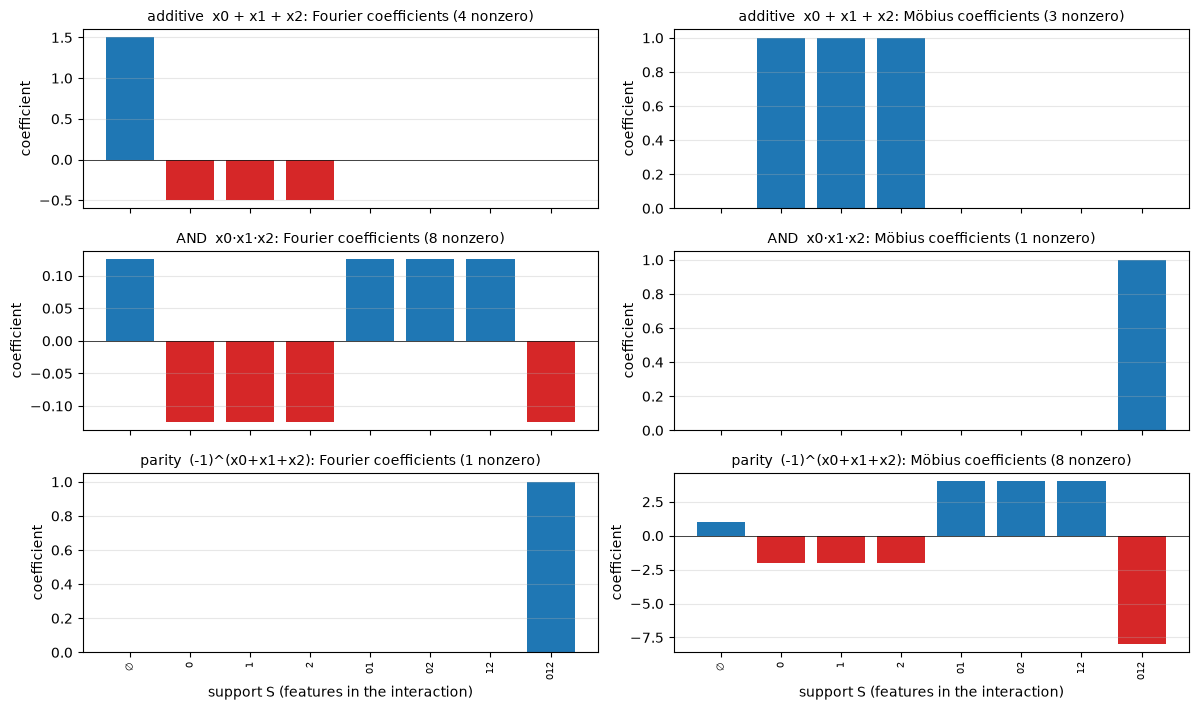

In [7]:
n_toy = 3
toy_masks = all_masks(n_toy)
toy_games = {
    "additive  x0 + x1 + x2": toy_masks.sum(1).astype(float),
    "AND  x0·x1·x2": toy_masks.prod(1).astype(float),
    "parity  (-1)^(x0+x1+x2)": (-1.0) ** toy_masks.sum(1),
}
toy_spectra = {
    name: (array_to_spectrum(fwht(values), tol=1e-12), array_to_spectrum(mobius_transform(values), tol=1e-12))
    for name, values in toy_games.items()
}
utils.plot_toy_spectra(toy_spectra, n_toy)

<details>
<summary>Help - how should I interpret this figure?</summary>

- The **additive** game is sparse in both bases: 3 Möbius coefficients (one per feature, all +1) and 4 Fourier coefficients (a constant 1.5 plus $-\tfrac12$ per feature, because $x_i = \tfrac12 - \tfrac12\chi_{\{i\}}$).
- The **AND** game has a single Möbius coefficient, $m(\{0,1,2\}) = 1$, but all 8 Fourier coefficients are nonzero with magnitude $\tfrac18$: expanding $\prod_i \tfrac12(1 - \chi_{\{i\}})$ produces every subset.
- The **parity** game is the mirror image: a single Fourier coefficient, $F(\{0,1,2\}) = 1$, and 8 Möbius coefficients whose magnitudes *grow* with the order, $(-2)^{|S|}$, reaching $-8$ at the top.

So "sparse" is not a property of a function alone; it's a property of a function *in a basis*. A degree-$d$ AND costs $2^d$ Fourier coefficients, so a spectrum of a few low-order
ANDs is still sparse in the Fourier basis (just a constant factor $2^d$ less so). A high-order parity, on the other hand, is a disaster in the Möbius basis. Notice also the
magnitudes in the parity row: Möbius coefficients can be much *larger* than the function's values. That will matter a lot in section 2️⃣.
</details>

### Exercise - convert a sparse Fourier spectrum to Möbius coefficients

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

SPEX and ProxySPEX both return a sparse **Fourier** spectrum, but we want to report interactions in the interpretable Möbius / Shapley language. The full transforms above work on
all $2^n$ values, which we won't have. Instead we convert term by term. Substitute $\chi_{\{i\}} = 1 - 2x_i$:

$$
F(S)\,\chi_S(x) = F(S) \prod_{i \in S} (1 - 2x_i) = F(S) \sum_{T \subseteq S} (-2)^{|T|} \prod_{i \in T} x_i ,
$$

so each Fourier term contributes to the Möbius coefficient of every subset $T$ of its support:

$$
m(T) = (-2)^{|T|} \sum_{S \supseteq T} F(S).
$$

Implement `fourier_to_mobius`, which loops over the terms of a sparse spectrum and accumulates their contributions to all subsets (use `itertools.combinations`). The cost is
$\sum_S 2^{|S|}$, which is small as long as the spectrum has low degree.

In [8]:
def fourier_to_mobius(spectrum: Spectrum) -> Spectrum:
    """Converts a sparse Fourier spectrum to the Möbius (AND-basis) coefficients of the same function."""
    sums = {}
    for support, coef in spectrum.items():
        for r in range(len(support) + 1):
            for subset in itertools.combinations(support, r):
                sums[subset] = sums.get(subset, 0.0) + coef
    return {subset: (-2.0) ** len(subset) * total for subset, total in sums.items()}


tests.test_fourier_to_mobius(fourier_to_mobius)

All tests in `test_fourier_to_mobius` passed!


<details>
<summary>Hint</summary>

First accumulate `sums[T] += F(S)` for every term `S` and every subset `T` of `S` (including `()` and `S` itself), then multiply each `sums[T]` by `(-2) ** len(T)` at the end.
Because `itertools.combinations` of a sorted tuple yields sorted tuples, the keys will automatically be in our canonical form.
</details>

### Exercise - Shapley values and Shapley interactions from Möbius coefficients

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Recall from [16.5] that the **Shapley interaction index** (SII) of a set $T$ has a very clean expression in terms of Möbius coefficients (Grabisch et al., 2000):

$$
I^{\text{SII}}(T) = \sum_{S \supseteq T} \frac{m(S)}{|S| - |T| + 1}.
$$

In words: every Möbius term $m(S)$ is shared out among the subsets of $S$, with the subsets of size $|T|$ each getting a fraction $1 / (|S| - |T| + 1)$. For a single feature, $|T|
= 1$ and the weight is $1 / |S|$: the Möbius term is split equally among its $|S|$ members. That's the **Shapley value**, $\phi_i = I^{\text{SII}}(\{i\}) = \sum_{S \ni i} m(S) /
|S|$.

Implement `shapley_interactions`, which returns the SII of every set $T$ with $1 \le |T| \le$ `max_order` that is a subset of some Möbius term (all other SIIs are zero). The test
checks your function against a brute-force implementation of the SII's definition in terms of discrete derivatives, which doesn't use Möbius coefficients at all.

In [9]:
def shapley_interactions(mobius: Spectrum, max_order: int = 2) -> Spectrum:
    """
    Shapley interaction indices I(T) = sum_{S superset of T} m(S) / (|S| - |T| + 1), for all 1 <= |T| <= max_order.
    The Shapley value of feature i is the entry for (i,).
    """
    out = {}
    for support, coef in mobius.items():
        for r in range(1, min(len(support), max_order) + 1):
            for subset in itertools.combinations(support, r):
                out[subset] = out.get(subset, 0.0) + coef / (len(support) - r + 1)
    return out


tests.test_shapley_interactions(shapley_interactions)

All tests in `test_shapley_interactions` passed!


Let's check our conventions against an independent implementation. If you have the [`shapiq`](https://github.com/mmschlk/shapiq) package installed (it's in the course requirements), the cell below compares your Shapley values and pairwise SII on a random 6-feature game with `shapiq.ExactComputer`, which computes them by brute force over coalitions. If `shapiq` isn't available, the cell just says so; the tests above already compare against a brute-force definition.

In [10]:
rng = np.random.default_rng(0)
check_values = rng.normal(size=2**6)
ours = shapley_interactions(array_to_spectrum(mobius_transform(check_values)), max_order=2)
try:
    import shapiq

    exact = shapiq.ExactComputer(lambda X: check_values[mask_index(np.asarray(X, dtype=int))], n_players=6)
    sii_ref = exact("SII", order=2)
    max_diff = max(abs(ours[T] - sii_ref[T]) for T in ours)
    print(f"shapiq {shapiq.__version__}: max |our SII - shapiq SII| over {len(ours)} sets = {max_diff:.2e}")
except ImportError:
    print("shapiq not installed: skipping the cross-check")

shapiq 1.8.0: max |our SII - shapiq SII| over 21 sets = 7.77e-16


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">shapiq 1.5.2: max |our SII - shapiq SII| over 21 sets = 7.77e-16</pre>

</details>

Here's a useful sanity check to do in your head, using the toy games from the figure. In the **AND** game, $m(\{0,1,2\}) = 1$ is the only Möbius term, so each feature has Shapley
value $\tfrac13$ and each pair has SII $\tfrac12$. In the **parity** game the Shapley values are all $-\tfrac23$ (they must sum to $f(\mathbf{1}) - f(\mathbf{0}) = -1 - 1 = -2$),
which tells you nothing about the fact that the output flips with *every* feature. First-order attributions can't represent a function like that, however you compute them.

## Summary of 1️⃣

- A value function on masks can be written exactly in the Möbius (AND) basis or the Fourier (parity) basis. The two are related by $m(T) = (-2)^{|T|}\sum_{S \supseteq T} F(S)$.
- Both full transforms cost $O(n 2^n)$ with butterfly algorithms, so they're only usable for small $n$ (16 is fine, 30 isn't).
- Sparsity is basis-dependent. Low-order ANDs are sparse in both bases; parities are sparse only in the Fourier basis.
- Shapley values and Shapley interaction indices are fixed linear functions of the Möbius coefficients, so once we have a sparse Fourier spectrum, we get every attribution and interaction index cheaply.

What we haven't answered is whether the functions we care about, real models under masking, are sparse in *any* basis. Let's measure it.

# 2️⃣ How Sparse Is a Real Model?

> ##### Learning Objectives
>
> - Turn a masking intervention on a language model into a value function on the Boolean hypercube
> - Use Parseval's theorem to read the best possible k-term (and best possible additive) explanation straight off the spectrum
> - See that GPT-2's spectrum is concentrated and low-order, and that how interactive it looks depends on the output read-out
> - Understand why exact Möbius coefficients of a real model are numerically meaningless at high order, while Fourier coefficients are not

## The word-deletion game

We'll use GPT-2 Small and the IOI sentence from the introduction. Our features are its 16 words; the final token `" to"` is always kept, since that's where we read off the
prediction.

What should it mean to "remove" a word? There are several options: delete it, replace it with a placeholder like `"_"`, or replace it with a random word. They define *different*
value functions, and therefore different interactions. We'll use **deletion**, because it doesn't introduce any new tokens. To keep all masks in one batch of fixed length, we
implement deletion with the attention mask: masked tokens are never attended to, and TransformerLens computes position ids as the cumulative sum of the attention mask, so the kept
tokens get exactly the positions they'd have if the masked words had been deleted. You'll check that this really is equivalent to deletion.

`utils.tokenize_words` splits the sentence into words, tokenises each one (a word can span several tokens: `"Yesterday,"` is two), and returns a `token_to_word` map with entry $-1$
for tokens that are never masked (BOS and the final `" to"`).

In [11]:
model = HookedTransformer.from_pretrained("gpt2-small", device=device)
model.requires_grad_(False)

IOI_TEXT = "Yesterday, when Mary and John went to the busy store, John happily gave a cold drink"
words, ioi_tokens, ioi_token_to_word = utils.tokenize_words(model, IOI_TEXT, " to")
n_words = len(words)
MARY, JOHN = model.to_single_token(" Mary"), model.to_single_token(" John")

print(f"{n_words} words, {ioi_tokens.shape[1]} tokens")
print([model.to_string(tok) for tok in ioi_tokens[0]])
print(ioi_token_to_word.tolist())

/tmp/ipykernel_4078055/1872623011.py:1: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2-small", device=device)


Loaded pretrained model gpt2-small into HookedTransformer
16 words, 20 tokens
['<|endoftext|>', 'Yesterday', ',', ' when', ' Mary', ' and', ' John', ' went', ' to', ' the', ' busy', ' store', ',', ' John', ' happily', ' gave', ' a', ' cold', ' drink', ' to']
[-1, 0, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 9, 10, 11, 12, 13, 14, 15, -1]


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">16 words, 20 tokens
['&lt;|endoftext|&gt;', 'Yesterday', ',', ' when', ' Mary', ' and', ' John', ' went', ' to', ' the', ' busy', ' store', ',', ' John', ' happily', ' gave', ' a', ' cold', ' drink', ' to']
[-1, 0, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 9, 10, 11, 12, 13, 14, 15, -1]</pre>

</details>

### Exercise - implement `masked_final_logits`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

Implement `masked_final_logits`. Given the prompt's tokens `(1, seq)`, the `token_to_word` map `(seq,)`, and a batch of word masks `(batch, n)`, it should:

1. Build an attention mask of shape `(batch, seq)`: 1 for tokens that are never masked (`token_to_word == -1`), and for every other token, the mask bit of the word it belongs to.
2. Run the model on the repeated tokens with `attention_mask=...`, and return the logits at the **final** position, shape `(batch, d_vocab)`.

Memory matters here: we'll push 65,536 masks through the model in batches, and the full logits tensor for a batch of 512 sequences of 20 tokens is already 2 GB. So don't compute
logits at every position. Instead, run the model with `stop_at_layer=model.cfg.n_layers` (which returns the residual stream after the last block), take the final position, and
apply `model.ln_final` and `model.unembed` yourself.

The test compares your output with actually deleting the masked words' tokens and running the model normally.

In [12]:
@t.inference_mode()
def masked_final_logits(
    model: HookedTransformer,
    tokens: Int[Tensor, "1 seq"],
    token_to_word: Int[Tensor, " seq"],
    masks: Int[Tensor, "batch n"],
) -> Float[Tensor, "batch d_vocab"]:
    """Final-position logits when each masked word's tokens are removed (via the attention mask)."""
    masks = masks.to(tokens.device).long()
    attention_mask = t.ones(masks.shape[0], tokens.shape[1], dtype=t.long, device=tokens.device)
    maskable = token_to_word >= 0
    attention_mask[:, maskable] = masks[:, token_to_word[maskable]]
    resid = model(tokens.expand(masks.shape[0], -1), attention_mask=attention_mask, stop_at_layer=model.cfg.n_layers)
    return model.unembed(model.ln_final(resid[:, -1]))


tests.test_masked_final_logits(masked_final_logits, model)

All tests in `test_masked_final_logits` passed!


<details>
<summary>Hint</summary>

`masks[:, token_to_word[maskable]]` picks, for every maskable token, the bit of the word it belongs to (a word with two tokens gets its bit twice). Assign that into the
corresponding columns of an all-ones attention mask. Then `model(tokens.expand(batch, -1), attention_mask=attention_mask, stop_at_layer=model.cfg.n_layers)[:, -1]` is the final
residual stream at the last position.
</details>

<details>
<summary>Aside - why is this exactly deletion?</summary>

Two things change when you delete a token: later tokens can't attend to it, and every later token's position index shifts down by one. The attention mask handles the first. For the
second, TransformerLens computes the position ids as `attention_mask.cumsum(-1) - 1` whenever an attention mask is passed (this is how it supports left-padding), so a kept token's
position is the number of kept tokens before it. Since GPT-2 uses learned absolute position embeddings, that's exactly what deletion would give. The masked positions still get
*computed*, but nothing reads from them. (For a model with rotary embeddings you'd need to check how that implementation derives positions before relying on this.)
</details>

Next, a small wrapper turns this into a value function on numpy masks, batching and applying a **read-out** to the logits. We'll use two read-outs throughout:

- the **logit difference** `logit(" Mary") - logit(" John")`, the standard IOI metric, and
- the **probability** `p(" Mary")`.

They measure the same behaviour, but as we'll see they have very different interaction structure.

In [13]:
def make_value_function(
    model: HookedTransformer,
    tokens: Int[Tensor, "1 seq"],
    token_to_word: Int[Tensor, " seq"],
    readout: Callable[[Tensor], Tensor],
    batch_size: int = 512,
) -> Callable[[np.ndarray], np.ndarray]:
    """Returns f(masks) -> readout(final logits) as a float64 numpy array, evaluated in batches."""

    def f(masks: np.ndarray, progress: bool = False) -> np.ndarray:
        masks = t.as_tensor(np.asarray(masks), device=tokens.device)
        chunks = range(0, len(masks), batch_size)
        out = [
            readout(masked_final_logits(model, tokens, token_to_word, masks[i : i + batch_size]).float()).cpu()
            for i in (tqdm(chunks) if progress else chunks)
        ]
        return t.cat(out).numpy().astype(np.float64)

    return f


def ioi_readouts(logits: Tensor) -> Tensor:
    """(batch, d_vocab) -> (batch, 2): [logit(Mary) - logit(John), p(Mary)]."""
    return t.stack([logits[:, MARY] - logits[:, JOHN], logits.softmax(-1)[:, MARY]], dim=-1)

## The exact spectrum

Now for the expensive part: evaluate GPT-2 on **every** one of the $2^{16} = 65{,}536$ masks. This takes about 20-50 seconds on a GPU, depending on what else is running on it
(several minutes on a CPU; if you're on a CPU, you can shorten `IOI_TEXT` to 12 words for a 16x speed-up, though the numbers in the text won't match). We'll never do this again;
everything afterwards uses this table as ground truth.

In [14]:
ioi_value_both = make_value_function(model, ioi_tokens, ioi_token_to_word, ioi_readouts)
X_all = all_masks(n_words)

start = time.time()
table = ioi_value_both(X_all, progress=True)
print(f"Evaluated {len(X_all):,} masks in {time.time() - start:.0f}s")

exact_values = {"logit diff": table[:, 0], "p(Mary)": table[:, 1]}

# A few masks by hand: which words are dropped, and what happens to each read-out
drops = [[], [2], [4], [10], [4, 10], [12]]
rows = []
for drop in drops:
    mask = np.ones(n_words, dtype=int)
    mask[drop] = 0
    i = mask_index(mask[None])[0]
    rows.append({"dropped words": ", ".join(f"{words[d]}[{d}]" for d in drop) or "(none)",
                 "logit diff": exact_values["logit diff"][i], "p(Mary)": exact_values["p(Mary)"][i]})
print(pd.DataFrame(rows).set_index("dropped words").round(3).to_string())

  0%|          | 0/128 [00:00<?, ?it/s]

Evaluated 65,536 masks in 17s
                   logit diff  p(Mary)
dropped words                         
(none)                  2.692    0.595
Mary[2]                -4.477    0.002
John[4]                 1.063    0.096
John[10]               -0.404    0.037
John[4], John[10]       2.475    0.019
gave[12]               -0.100    0.014


<details>
<summary>Expected output (timings will vary)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Evaluated 65,536 masks in 17s
                   logit diff  p(Mary)
dropped words                         
(none)                  2.692    0.595
Mary[2]                -4.476    0.002
John[4]                 1.063    0.096
John[10]               -0.404    0.037
John[4], John[10]       2.475    0.019
gave[12]               -0.100    0.014</pre>

</details>

These are the numbers from the introduction (indices in brackets are word positions; there are two Johns, at positions 4 and 10). Look at the `p(Mary)` column too: in probability
terms, *every* deletion hurts a lot, including deleting both Johns. The logit difference is a comparison between two names, and deleting both Johns keeps the comparison intact; the
probability of Mary also depends on how much mass goes to everything else in the vocabulary, and a mangled sentence spreads that mass around.

### Exercise - summarise a spectrum

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

How do we measure whether a spectrum is "sparse and low-degree"? The key tool is **Parseval's theorem**: because the characters are orthonormal under the uniform distribution,

$$
\operatorname{Var}_{x \sim \text{Unif}}[f(x)] = \sum_{S \neq \emptyset} F(S)^2 .
$$

So the squared coefficients ("energies") tell us how the variance of the model's output, over random masks, is split between interactions. Better still, if we approximate $f$ by
keeping some set $\mathcal{K}$ of its true coefficients, the approximation's $R^2$ on uniformly random masks is exactly the fraction of non-constant energy in $\mathcal{K}$. That
gives two summaries with a direct meaning:

- `degree_energy(F)`: for each degree $d = 1, \ldots, n$, the fraction of non-constant energy in coefficients with $|S| = d$. The first entry is the $R^2$ of the **best possible additive (first-order) explanation**: no attribution method that assigns one number per feature can be more faithful than this on random masks.
- `topk_energy(F)`: entry $k-1$ is the fraction of non-constant energy in the $k$ largest coefficients (by magnitude, excluding the constant), i.e. the $R^2$ of the **best possible $k$-term explanation**.

Implement both. `F` is a full array of $2^n$ Fourier coefficients in index order (so the degree of entry $i$ is the number of 1-bits in $i$).

In [15]:
def degree_energy(F: Float[np.ndarray, " two_pow_n"]) -> Float[np.ndarray, " n"]:
    """Fraction of non-constant energy sum_{|S|=d} F(S)^2 / sum_{S != empty} F(S)^2, for d = 1..n."""
    n = int(np.log2(len(F)))
    degree = np.array([bin(i).count("1") for i in range(len(F))])
    energy = F**2
    total = energy[1:].sum()
    return np.array([energy[degree == d].sum() / total for d in range(1, n + 1)])


def topk_energy(F: Float[np.ndarray, " two_pow_n"]) -> Float[np.ndarray, " two_pow_n_minus_1"]:
    """Entry k-1: fraction of non-constant energy in the k largest non-constant coefficients."""
    energy = np.sort(F[1:] ** 2)[::-1]
    return np.cumsum(energy) / energy.sum()


tests.test_spectrum_summaries(degree_energy, topk_energy)

All tests in `test_spectrum_summaries` passed!


Now the signature result of this part. We compute both exact spectra with your `fwht`, and compare them with a **control**: the same 65,536 values of `p(Mary)`, randomly permuted
across masks. The shuffled function has the same distribution of outputs, but none of the structure: any concentration that survives shuffling is an artefact of the measurement,
not of the model.

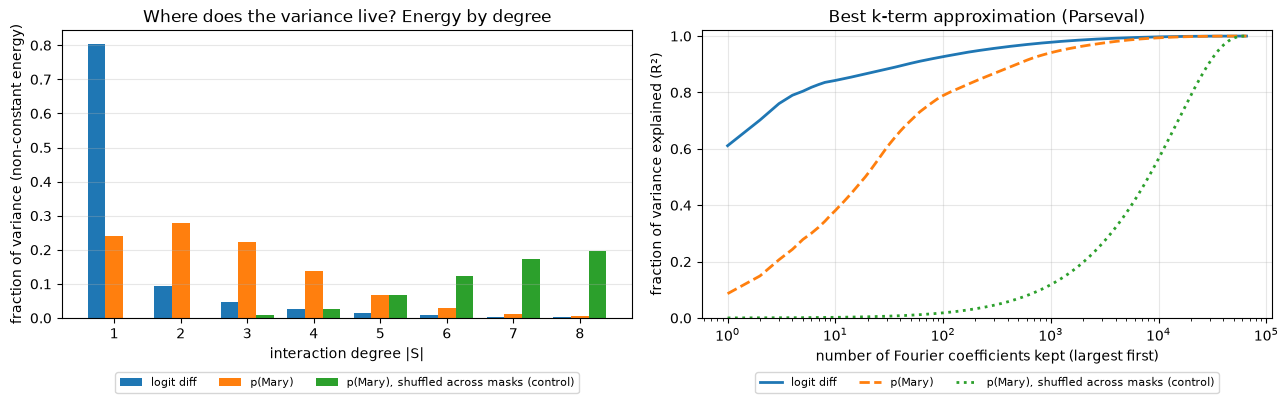

                  degree 1  degree 2  degree 3  degree <= 3  top 10  top 50  top 200  top 1000
logit diff           0.803     0.095     0.047        0.945   0.843   0.903    0.947     0.978
p(Mary)              0.241     0.279     0.223        0.743   0.381   0.700    0.841     0.941
shuffled control     0.000     0.001     0.009        0.010   0.002   0.010    0.033     0.118


In [16]:
exact_F = {name: fwht(values) for name, values in exact_values.items()}
shuffled_F = fwht(np.random.default_rng(0).permutation(exact_values["p(Mary)"]))

utils.plot_sparsity(
    {"logit diff": exact_F["logit diff"], "p(Mary)": exact_F["p(Mary)"], "p(Mary), shuffled across masks (control)": shuffled_F},
    degree_energy,
    topk_energy,
)

summary = {}
for name, F in [*exact_F.items(), ("shuffled control", shuffled_F)]:
    de, tk = degree_energy(F), topk_energy(F)
    summary[name] = {"degree 1": de[0], "degree 2": de[1], "degree 3": de[2], "degree <= 3": de[:3].sum(),
                     "top 10": tk[9], "top 50": tk[49], "top 200": tk[199], "top 1000": tk[999]}
print(pd.DataFrame(summary).T.round(3).to_string())

<details>
<summary>Expected output (table)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                  degree 1  degree 2  degree 3  degree &lt;= 3  top 10  top 50  top 200  top 1000
logit diff           0.803     0.095     0.047        0.945   0.843   0.903    0.947     0.978
p(Mary)              0.241     0.279     0.223        0.743   0.381   0.700    0.841     0.941
shuffled control     0.000     0.001     0.009        0.010   0.002   0.010    0.033     0.118</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

**Concentration.** Both read-outs are far more concentrated than the shuffled control. For the logit difference, the 10 largest of the 65,535 non-constant Fourier coefficients
explain 84% of the variance over random masks, and the 200 largest explain 95%. For `p(Mary)` the same numbers are 38% and 84%. The shuffled control has exactly the same 65,536
values, but its 200 largest coefficients explain only 3.3%, and 1,000 explain 12%: its spectrum is essentially flat, which is what "no structure" looks like in this basis. So the
concentration is a property of the model's behaviour, not of the distribution of its outputs.

**Low order.** For both read-outs most of the energy sits at low degree: 94.5% of the logit difference's variance and 74% of `p(Mary)`'s is in terms of degree $\le 3$. The shuffled
control spreads its energy in proportion to how many coefficients there are at each degree ($\binom{16}{d}$, which peaks at $d = 8$), so it has only 1% at degree $\le 3$.

**The read-out matters.** The logit difference is mostly *additive*: 80% of its variance is first-order. `p(Mary)` is mostly *interactions*: only 24% is first-order, and degrees 2,
3 and 4 each carry more than 10%. It's the same model and the same masks. Logits are (roughly) sums of contributions written into the residual stream by components that read
different words, so the effects of deleting words tend to add up. The probability passes the logits through a softmax, which saturates: `p(Mary)` is close to zero unless
*everything* the model needs is present, which is AND-like behaviour, and an AND of $d$ words has Fourier mass at every degree up to $d$.

**Ceilings for free.** By Parseval, the degree-1 bar is the $R^2$ of the best possible additive explanation on random masks: 0.80 for the logit difference, 0.24 for `p(Mary)`. No
attribution method that assigns one number per word can be more faithful than that. Keep these two numbers in mind for section 5️⃣.
</details>

Which coefficients are the big ones? The cell below lists the largest non-constant Fourier coefficients of each read-out, labelled by words (with their positions, so the two Johns
stay distinct).

In [17]:
for name, F in exact_F.items():
    spectrum = array_to_spectrum(F)
    top = sorted(((S, v) for S, v in spectrum.items() if S), key=lambda kv: -abs(kv[1]))[:10]
    print(f"{name}: largest Fourier coefficients")
    for S, v in top:
        print(f"  {v:+.4f}  {utils.support_label(S, words)}")

logit diff: largest Fourier coefficients
  -1.4942  Mary[2]
  +0.5774  John[10]
  +0.4611  John[4]
  +0.3296  cold[14]
  +0.2277  Mary[2] × John[4]
  +0.2258  John[4] × John[10]
  +0.1891  Mary[2] × gave[12]
  +0.1662  cold[14] × drink[15]
  -0.1134  the[7]
  +0.1113  Mary[2] × and[3]
p(Mary): largest Fourier coefficients
  -0.0197  Mary[2]
  -0.0168  gave[12]
  +0.0160  Mary[2] × gave[12]
  -0.0129  John[10]
  +0.0125  Mary[2] × John[10]
  +0.0099  John[10] × gave[12]
  -0.0098  Mary[2] × John[10] × gave[12]
  +0.0097  Mary[2] × and[3]
  -0.0097  and[3]
  -0.0087  Mary[2] × and[3] × gave[12]


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">logit diff: largest Fourier coefficients
  -1.4942  Mary[2]
  +0.5774  John[10]
  +0.4611  John[4]
  +0.3296  cold[14]
  +0.2277  Mary[2] × John[4]
  +0.2258  John[4] × John[10]
  +0.1891  Mary[2] × gave[12]
  +0.1662  cold[14] × drink[15]
  -0.1134  the[7]
  +0.1113  Mary[2] × and[3]
p(Mary): largest Fourier coefficients
  -0.0197  Mary[2]
  -0.0168  gave[12]
  +0.0160  Mary[2] × gave[12]
  -0.0129  John[10]
  +0.0125  Mary[2] × John[10]
  +0.0099  John[10] × gave[12]
  -0.0098  Mary[2] × John[10] × gave[12]
  +0.0097  Mary[2] × and[3]
  -0.0097  and[3]
  -0.0087  Mary[2] × and[3] × gave[12]</pre>

</details>

<details>
<summary>Help - how should I read these?</summary>

Remember the sign convention: a *negative* coefficient on a single word means that keeping the word *increases* the output on average (the average effect of switching word $i$ from
removed to kept is $-2F(\{i\})$).

- **Logit difference.** Mary dominates: keeping Mary raises the logit difference by about $2 \times 1.49 \approx 3$ logits on average. Both Johns have positive coefficients, so on average keeping a John *lowers* the logit difference. The first interactions are Mary × John[4] and **John[4] × John[10]**, the duplicated-name interaction from the introduction, followed by Mary × gave and cold × drink (two adjacent words that read as a phrase).
- **p(Mary).** The list is the Fourier fingerprint of an AND. Mary, gave and John[10], their three pairs and their triple appear with alternating signs (singletons negative, pairs positive, triple negative), which is exactly the pattern of the AND toy game in section 1️⃣. In words: Mary gets high probability only when the name, the verb that sets up the recipient slot, and the second John are all present.
</details>

### Why not just use the Möbius coefficients?

The Möbius basis is the more interpretable one, so why bother with Fourier at all? Let's look at the exact Möbius coefficients of the same game.

In [18]:
for name, values in exact_values.items():
    m = mobius_transform(values)
    F = exact_F[name]
    largest = np.argsort(-np.abs(m))[:6]
    print(f"{name}: values in [{values.min():.2f}, {values.max():.2f}],  max |F(S)| = {np.abs(F[1:]).max():.3f},  "
          f"max |m(S)| = {np.abs(m).max():.2f}")
    print("   six largest |m(S)|, as (number of words in S, m(S)): "
          + ", ".join(f"({bin(i).count('1')}, {m[i]:+.2f})" for i in largest))

logit diff: values in [-7.62, 4.33],  max |F(S)| = 1.494,  max |m(S)| = 22.63
   six largest |m(S)|, as (number of words in S, m(S)): (14, -22.63), (13, +19.71), (13, +19.35), (12, -16.85), (13, +16.52), (13, +16.02)
p(Mary): values in [0.00, 0.80],  max |F(S)| = 0.020,  max |m(S)| = 0.87
   six largest |m(S)|, as (number of words in S, m(S)): (9, +0.87), (10, -0.84), (7, +0.82), (9, +0.79), (8, -0.77), (10, -0.75)


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">logit diff: values in [-7.62, 4.33],  max |F(S)| = 1.494,  max |m(S)| = 22.63
   six largest |m(S)|, as (number of words in S, m(S)): (14, -22.63), (13, +19.71), (13, +19.35), (12, -16.85), (13, +16.52), (13, +16.02)
p(Mary): values in [0.00, 0.80],  max |F(S)| = 0.020,  max |m(S)| = 0.87
   six largest |m(S)|, as (number of words in S, m(S)): (9, +0.87), (10, -0.84), (7, +0.82), (9, +0.79), (8, -0.77), (10, -0.75)</pre>

</details>

For the logit difference, the six largest exact Möbius coefficients all belong to sets of 12-14 words, they alternate in sign, and the largest (−22.6) is three times larger than
anything the function itself ever outputs (its values lie between −7.6 and 4.3). For `p(Mary)` the effect is milder but the same in kind: the largest coefficients sit on sets of
7-10 words, with alternating signs, and are as large as the largest probability. These are not "giant 14-way interactions" in any meaningful sense. Recall that $m(S) = \sum_{T
\subseteq S} (-1)^{|S|-|T|} f(T)$ is an alternating sum of $2^{|S|}$ values: a 14th-order discrete derivative. Tiny irregularities in $f$ (the model's response to strange,
heavily-masked inputs) get added up with alternating signs and amplified by up to $2^{|S|}$, just like the $(-2)^{|S|}$ growth you saw for the parity toy game. A Fourier
coefficient, by contrast, is an *average* of $\pm f(x)$, so $|F(S)| \le \max_x |f(x)|$ always.

This is the practical reason to *find* interactions in the Fourier basis, where small high-order coefficients really are small, and only *convert* a truncated, low-order Fourier
spectrum to Möbius / Shapley language at the end. The Shapley values and SII themselves are fine either way: they're weighted averages, and are stable even when computed from these
wild exact Möbius coefficients.

## Summary of 2️⃣

- Masking words with the attention mask defines a value function on $\{0,1\}^{16}$ that is exactly word deletion.
- GPT-2's spectrum on this sentence is far more concentrated than a shuffled control, and dominated by low-order terms. A few hundred of the 65,536 coefficients explain most of the variance.
- How *interactive* the behaviour looks depends on the read-out. The logit difference is mostly additive; the probability of the answer is mostly interactions (the softmax makes the model's output AND-like: Mary only gets high probability when everything needed is present).
- By Parseval, degree energies give hard ceilings: no first-order attribution can explain more than about 80% of the logit difference's variance on random masks, or 24% of the probability's.
- Exact high-order Möbius coefficients of a real model are numerically meaningless; work in the Fourier basis and convert at the end.

This is the empirical premise of SPEX and ProxySPEX: value functions of real models are **approximately sparse and low-degree in the Fourier basis**. The question now is how to
find those few hundred coefficients *without* evaluating all $2^n$ masks, because for $n = 100$ we can't.

# 3️⃣ SPEX: Sparse Recovery from Aliased Queries

> ##### Learning Objectives
>
> - Derive and verify the aliasing identity that connects a $2^b$-point Walsh transform to the full spectrum
> - Understand how delays turn support identification into a decoding problem, and why a BCH code solves it with $O(t \log n)$ queries
> - Implement singleton detection, soft (Chase) decoding and the peeling decoder
> - Produce query-budget vs recovery curves, and identify the sparsity and degree assumptions from how the method fails

## The plan

Suppose $f$ has $s$ nonzero Fourier coefficients of degree at most $t$, out of $2^n$ possible ones. We get to choose which masks to query. How few queries can we get away with?

Counting suggests the answer can be very small. Each coefficient is described by a support (about $t \log_2 n$ bits) and a value, so $s$ coefficients are described by roughly $s \,
t \log n$ numbers, and one might hope that about that many queries suffice. SPEX (building on earlier sparse Walsh-Hadamard transform algorithms such as Li, Bradley & Ramchandran's
SPRIGHT) achieves this, in four steps:

1. **Aliasing.** Query $f$ on a structured set of $2^b$ masks (a random $b$-dimensional subspace of the hypercube) and take a small $2^b$-point Walsh transform. Each output **bin** is the sum of all the Fourier coefficients that *hash* to it. With $2^b \approx s$ bins, most bins hold zero or one coefficient.
2. **Delays.** Repeat the same queries with the masks shifted (XORed) by a few fixed patterns. Shifting multiplies each coefficient by a sign that depends on its support, so the sign pattern across shifts encodes *which* support is in a bin.
3. **Coding.** Choose the shift patterns to be the rows of the parity-check matrix of an error-correcting (BCH) code. Then decoding the support from the sign pattern is exactly syndrome decoding, and needs only $O(t \log n)$ shifts instead of $n$.
4. **Peeling.** Bins with two or more coefficients (collisions) can't be decoded directly. But if we use a few independent hashes, a coefficient that collides in one hash is probably alone in another. Decode it there, subtract it from every bin it lands in, and repeat. Collisions dissolve one by one.

We'll build each step, and test them on **planted games**: functions given by a random sparse spectrum, so that we know the right answer and can check recovery exactly. We'll come
back to GPT-2 in section 5️⃣.

Planted games are given to SPEX as an ordinary value function, which we make with `spectrum_oracle` below. (It evaluates in chunks, because dense planted spectra have thousands of
terms.)

In [19]:
def spectrum_oracle(spectrum: Spectrum, chunk: int = 4096) -> Callable[[np.ndarray], np.ndarray]:
    """A value function whose Fourier spectrum is exactly `spectrum`."""

    def f(masks: np.ndarray) -> np.ndarray:
        masks = np.asarray(masks)
        return np.concatenate([predict_spectrum(spectrum, masks[i : i + chunk]) for i in range(0, len(masks), chunk)])

    return f

## Aliasing: folding the hypercube

Pick a random binary matrix $M \in \{0,1\}^{n \times b}$ and a **delay** (shift) $d \in \{0,1\}^n$. For each of the $2^b$ small masks $\ell \in \{0,1\}^b$, query $f$ at the
full-size mask

$$
x = M\ell + d \pmod 2 .
$$

The masks $\{M\ell\}$ form a $b$-dimensional linear subspace of the hypercube (a random "slice" of it), and $d$ translates that slice. Now take the normalised $2^b$-point Walsh
transform of these $2^b$ values. A two-line calculation (expand $f$ in its Fourier series and swap the sums; see the dropdown) gives the **aliasing identity**:

$$
U_d(j) = \frac{1}{2^b}\sum_{\ell} f(M\ell + d)\,(-1)^{j \cdot \ell} = \sum_{k \,:\, M^\top k \,=\, j} F(k)\,(-1)^{d \cdot k} ,
$$

where $k \in \{0,1\}^n$ is the indicator vector of a support and all arithmetic in $M^\top k$ is mod 2. In words:

- Every Fourier coefficient $F(k)$ lands in exactly one **bin** $j = M^\top k$ (a $b$-bit hash of its support).
- Each bin holds the sum of all coefficients that hash to it, each multiplied by a **sign** $(-1)^{d \cdot k}$ that depends on the delay.

With the zero delay $d = 0$, bin $j$ is just the sum of the coefficients hashing there. That's already useful: if the bin holds a single coefficient (a **singleton**), we've
measured its value with $2^b$ queries, regardless of $n$. But we don't know *which* $k$ it was. That's what the other delays are for.

<details>
<summary>Derivation of the aliasing identity</summary>

Substituting $f(x) = \sum_k F(k) (-1)^{k \cdot x}$ with $x = M\ell + d$:

$$
U_d(j) = \frac{1}{2^b}\sum_\ell \sum_k F(k)\,(-1)^{k \cdot (M\ell + d)}(-1)^{j\cdot\ell} = \sum_k F(k)(-1)^{k\cdot d}\;\frac{1}{2^b}\sum_\ell (-1)^{(M^\top k + j)\cdot \ell} .
$$

Here we used $k \cdot M\ell = (M^\top k)\cdot \ell$. The inner average over $\ell$ is 1 if $M^\top k + j = 0 \pmod 2$, i.e. $M^\top k = j$, and 0 otherwise (characters of
$\{0,1\}^b$ are orthogonal). That leaves exactly the coefficients with $M^\top k = j$.
</details>

We'll index the small masks $\ell$ in the same order as `all_masks(b)`, so that the bin index $j$ is the integer whose bits (most significant first) are $M^\top k$. The function
`bin_index(M, support)` below computes this for a support.

In [20]:
def bin_index(M: Int[np.ndarray, "n b"], support: tuple[int, ...]) -> int:
    """The bin j = M^T k (as an integer, first column of M = most significant bit) that a support hashes to."""
    b = M.shape[1]
    bits = M[list(support)].sum(0) % 2 if len(support) else np.zeros(b, dtype=np.int64)
    return int(bits @ (1 << np.arange(b - 1, -1, -1)))

### Exercise - implement `subsample_masks` and `aliased_bins`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement:

- `subsample_masks(M, delay)`, which returns the $2^b$ masks $M\ell + d \bmod 2$ as a `(2**b, n)` array, with row $r$ corresponding to $\ell$ = `all_masks(b)[r]`.
- `aliased_bins(f, M, delays)`, which takes a `(P, n)` array of delays (row 0 will always be the zero delay), queries `f` on the subsampled masks for every delay **in a single call** (stack them into one `(P * 2**b, n)` batch), and returns
    - `U`, the `(P, 2**b)` array of bin values, where `U[p]` is the Walsh transform of the $2^b$ values for delay `p`,
    - the `(P, 2**b, n)` array of masks that were queried.

The test checks the aliasing identity directly: it computes $\sum_{k: M^\top k = j} F(k)(-1)^{d\cdot k}$ by brute force from a known spectrum.

In [21]:
def subsample_masks(M: Int[np.ndarray, "n b"], delay: Int[np.ndarray, " n"]) -> Int[np.ndarray, "two_pow_b n"]:
    """The 2^b masks M @ ell + delay (mod 2), with ell running over all_masks(b) in order."""
    small = all_masks(M.shape[1])  # (2^b, b)
    return (small @ M.T + delay) % 2


def aliased_bins(
    f: Callable[[np.ndarray], np.ndarray], M: Int[np.ndarray, "n b"], delays: Int[np.ndarray, "P n"]
) -> tuple[Float[np.ndarray, "P two_pow_b"], Int[np.ndarray, "P two_pow_b n"]]:
    """Queries f on the subsampled masks for every delay, and Walsh-transforms each delay's 2^b values."""
    P, n = delays.shape
    masks = np.stack([subsample_masks(M, d) for d in delays])  # (P, 2^b, n)
    values = f(masks.reshape(-1, n)).reshape(P, -1)
    return fwht(values), masks


tests.test_subsample_masks(subsample_masks)
tests.test_aliased_bins(aliased_bins)

All tests in `test_subsample_masks` passed!
All tests in `test_aliased_bins` passed!


<details>
<summary>Hint</summary>

`all_masks(b)` has shape `(2**b, b)`; multiplying it by `M.T` (shape `(b, n)`) gives every $M\ell$ as a row. Add the delay (broadcast) and take `% 2`. For `aliased_bins`, `fwht`
already works along the last axis, so you can transform the whole `(P, 2**b)` array of values at once.
</details>

Let's look at the bins for a planted game: $n = 100$ features and 40 random coefficients of degree 1-3 (plus a constant), hashed into $2^5 = 32$ bins by one random $M$. We colour
each bin by how many true coefficients it holds, which we can compute because we know the truth (SPEX itself never sees this).

9 empty bins, 13 singletons, 10 collisions (41 coefficients incl. the constant, 32 bins)


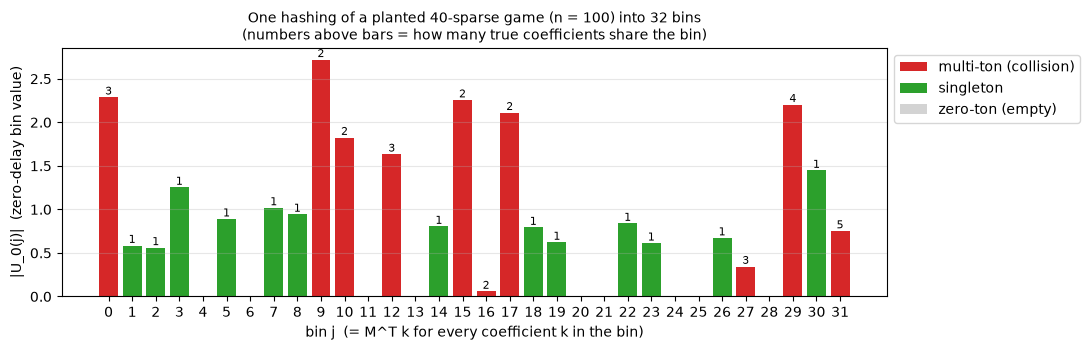

In [22]:
planted = utils.make_sparse_game(n=100, s=40, degrees=[1, 2, 3], seed=40)
f_planted = spectrum_oracle(planted)
M_example = np.random.default_rng(0).integers(0, 2, size=(100, 5))
U_example, _ = aliased_bins(f_planted, M_example, np.zeros((1, 100), dtype=np.int64))
occupancy = [[] for _ in range(32)]
for support in planted:
    occupancy[bin_index(M_example, support)].append(support)
counts = np.bincount([min(len(o), 2) for o in occupancy], minlength=3)
print(f"{counts[0]} empty bins, {counts[1]} singletons, {counts[2]} collisions (41 coefficients incl. the constant, 32 bins)")
utils.plot_bins(U_example[0], occupancy, "One hashing of a planted 40-sparse game (n = 100) into 32 bins")

<details>
<summary>Help - how should I interpret this?</summary>

With 41 coefficients (40 plus the constant) hashed into 32 bins, this hash leaves 9 bins empty, 13 holding exactly one coefficient, and 10 holding two or more (bin 31 holds five).
The 13 singletons could be decoded right away. The collisions can't: a value like $F(k_1) + F(k_2)$ doesn't belong to any single support.

Two things to notice. First, a bin's magnitude says nothing about its type: bin 16 holds two coefficients of opposite sign that nearly cancel, so it looks almost empty, while
several singletons are smaller than some collisions. SPEX will need another way to tell singletons apart. Second, look at what we paid: 32 queries summarise a function on $2^{100}$
masks, because aliasing only ever adds up the coefficients that are actually there.
</details>

## Delays: reading a support from signs

Suppose bin $j$ is a singleton holding $F(k)$. The aliasing identity says that with delay $d$ the bin reads $F(k)(-1)^{d\cdot k}$, so the ratio

$$
\frac{U_d(j)}{U_0(j)} = (-1)^{d \cdot k}
$$

is $\pm 1$, and tells us one bit of information about $k$: the parity $d \cdot k \bmod 2$. The value $F(k)$ cancels, so this works whatever the sign or size of the coefficient.

The simplest choice of delays is the $n$ unit vectors $d = e_1, \ldots, e_n$. Then $e_i \cdot k = k_i$, so the sign of each ratio directly reads off whether feature $i$ is in the
support. This "identity delay" design is what early sparse Walsh-Hadamard algorithms used.

### Exercise - read a support with identity delays

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Implement `read_support_identity`. Its input `u` has length $n + 1$: `u[0]` is the zero-delay value of a singleton bin, and `u[1 + i]` is its value under delay $e_i$. Return the
support as a tuple of feature indices.

In [23]:
def read_support_identity(u: Float[np.ndarray, " n_plus_1"]) -> tuple[int, ...]:
    """Decodes the support of a singleton bin measured with the zero delay followed by the n unit-vector delays."""
    return tuple(int(i) for i in np.flatnonzero(u[1:] / u[0] < 0))


tests.test_read_support_identity(read_support_identity)

All tests in `test_read_support_identity` passed!


Identity delays work, but they cost $n + 1$ copies of every subsampling pattern: for $n = 1000$ features and $2^b = 256$ bins that's 256,256 queries per hash. That throws away most
of what sparsity bought us. The fix is to notice that we're asking far too many questions: we know $k$ has at most $t$ ones, so it carries only about $t \log_2 n$ bits of
information. We should need only about that many delays.

## Coding the delays: BCH codes

Stack the (non-zero) delays as the rows of a $p \times n$ binary matrix $D$. For a singleton with support $k$, the sign bits we observe are

$$
\text{bits} = D k \pmod 2 .
$$

This is a familiar object from coding theory: if $D$ is the **parity-check matrix** of a code, then $Dk$ is the **syndrome** of the "error pattern" $k$. A code that can correct $t$
errors is one where every error pattern of weight $\le t$ has a *different* syndrome, and comes with an algorithm that recovers the error pattern from its syndrome. Error
correction is exactly what we need: our "errors" are the features in the support.

SPEX uses **binary BCH codes** (Bose, Chaudhuri & Hocquenghem, 1959-60), which are the classic family of $t$-error-correcting codes with a short syndrome and an efficient algebraic
decoder. Here's the construction. Let $m$ be the smallest integer with $2^m - 1 \ge n$, and let $\alpha$ be a primitive element of the finite field $\mathrm{GF}(2^m)$, so that
$\alpha^0, \alpha^1, \ldots, \alpha^{2^m - 2}$ are all the nonzero field elements. Each field element is an $m$-bit vector. The parity-check matrix has one column per feature $i$:

$$
D_{:, i} = \begin{pmatrix} \alpha^{i} \\ \alpha^{3i} \\ \alpha^{5i} \\ \vdots \\ \alpha^{(2t-1) i} \end{pmatrix} \quad \text{(each entry written as } m \text{ bits)},
$$

so $D$ has $p = mt \approx t \log_2 n$ rows. If $k$ has ones at positions $i_1, \ldots, i_w$, the syndrome's blocks are the field sums $S_r = \alpha^{r i_1} + \cdots + \alpha^{r
i_w}$ for odd $r$ (in characteristic 2, addition is XOR). Recovering $\{i_1, \ldots, i_w\}$ from these power sums is a classic algebra problem with a neat solution, which we'll get
to in a moment.

You don't need to know anything about finite fields beyond the following, which `utils.GaloisField(m)` provides:

- elements are integers $0, \ldots, 2^m - 1$, whose bits are the $m$ coordinates (bit $q$ is row $q$ of the block);
- `gf.exp[e]` is $\alpha^e$ (for $0 \le e < 2(2^m - 1)$), and `gf.log[a]` is the $e$ with $\alpha^e = a$;
- `gf.mul(a, b)` and `gf.inv(a)` multiply and invert; addition is `a ^ b`;
- $\alpha^{2^m - 1} = 1$, so exponents can be reduced modulo `gf.N` $= 2^m - 1$.

Building the tables is a Python loop over all $2^m$ elements, and we'll decode thousands of bins, so use `utils.galois_field(m)` (imported as `galois_field`), which returns a
cached `GaloisField(m)`.

In [24]:
gf = GaloisField(4)
print("alpha^0..alpha^15 in GF(16):", gf.exp[:16].tolist())
print("alpha^3 * alpha^14 =", gf.mul(gf.exp[3], gf.exp[14]), "= alpha^(17 mod 15) =", gf.exp[2])

alpha^0..alpha^15 in GF(16): [1, 2, 4, 8, 3, 6, 12, 11, 5, 10, 7, 14, 15, 13, 9, 1]
alpha^3 * alpha^14 = 4 = alpha^(17 mod 15) = 4


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">alpha^0..alpha^15 in GF(16): [1, 2, 4, 8, 3, 6, 12, 11, 5, 10, 7, 14, 15, 13, 9, 1]
alpha^3 * alpha^14 = 4 = alpha^(17 mod 15) = 4</pre>

</details>

Every nonzero element of the field appears exactly once among $\alpha^0, \ldots, \alpha^{14}$, and then the sequence repeats.

### Exercise - build the BCH delay matrix

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `bch_delay_matrix(n, t)`, which returns the $mt \times n$ binary matrix $D$ described above, with $m$ = `bch_field_degree(n)`. Block $r = 0, \ldots, t-1$ consists of rows
$rm, \ldots, rm + m - 1$, and its column $i$ holds the bits of $\alpha^{(2r+1)i}$, least significant bit in the first row of the block.

The test checks the property that actually matters: for a small code, every support of size at most $t$ produces a different syndrome.

In [25]:
def bch_delay_matrix(n: int, t: int) -> Int[np.ndarray, "m_times_t n"]:
    """Parity-check matrix of the (shortened) binary BCH code correcting t errors, used as SPEX's delays."""
    m = bch_field_degree(n)
    gf = galois_field(m)  # cached GaloisField(m)
    blocks = []
    for r in range(t):
        elements = gf.exp[((2 * r + 1) * np.arange(n)) % gf.N]  # alpha^((2r+1) i) for each feature i
        blocks.append((elements[None, :] >> np.arange(m)[:, None]) & 1)  # (m, n): bit q in row q
    return np.concatenate(blocks).astype(np.int64)


tests.test_bch_delay_matrix(bch_delay_matrix)

All tests in `test_bch_delay_matrix` passed!


<details>
<summary>Hint</summary>

For block `r`, `gf.exp[((2 * r + 1) * np.arange(n)) % gf.N]` gives the $n$ field elements as integers. To turn a vector of integers into an `(m, n)` bit matrix, use
`(elements[None, :] >> np.arange(m)[:, None]) & 1`. Concatenate the $t$ blocks along axis 0.
</details>

## Decoding a BCH syndrome

Given the observed bits $Dk$, we want the positions $i_1, \ldots, i_w$ ($w \le t$) of the ones in $k$. Write $X_q = \alpha^{i_q}$ for the unknown **error locators**. Reading the
bits back as field elements gives the odd power sums

$$
S_1 = \sum_q X_q, \quad S_3 = \sum_q X_q^3, \quad \ldots, \quad S_{2t-1} = \sum_q X_q^{2t-1} ,
$$

and in characteristic 2 the even ones come for free: $S_{2r} = \sum_q X_q^{2r} = \big(\sum_q X_q^{r}\big)^2 = S_r^2$, since squaring is additive ($(a+b)^2 = a^2 + b^2$ when $1 + 1
= 0$).

The decoding goes in two steps:

1. **Find the error-locator polynomial** $\Lambda(z) = \prod_{q=1}^w (1 + X_q z) = 1 + \Lambda_1 z + \cdots + \Lambda_w z^w$. Its coefficients are linked to the power sums $S_1, \ldots, S_{2t}$ by a linear recurrence (Newton's identities), and the **Berlekamp-Massey** algorithm finds the shortest recurrence that generates a given sequence. It's provided below: it's a beautiful algorithm, but it's general-purpose sequence analysis rather than anything specific to SPEX. (Implementing it yourself is a bonus exercise.)
2. **Find the roots** of $\Lambda$. The roots are $z = X_q^{-1} = \alpha^{-i_q}$, so we can simply test every feature position $i = 0, \ldots, n-1$: position $i$ is in the support iff $\Lambda(\alpha^{-i}) = 0$. This brute-force root search is called the **Chien search**, and it costs $O(nt)$, nothing like enumerating all $\binom{n}{t}$ supports.

If $\Lambda$ has degree $L > t$, or doesn't have exactly $L$ roots among the $n$ positions, then the bits weren't the syndrome of any support of size $\le t$, and we report failure
(`None`). In SPEX this happens a lot, and usefully: it's how we detect that a bin is *not* a clean singleton.

In [26]:
def berlekamp_massey(syndromes: list[int], gf: GaloisField) -> list[int]:
    """
    Shortest linear recurrence (connection polynomial) generating the sequence S_1, ..., S_2t over GF(2^m).
    Returns the coefficients [1, Lambda_1, ..., Lambda_L] of the error-locator polynomial, in increasing powers of z.
    """
    C, B = [1], [1]  # current and previous connection polynomials
    L, shift, b = 0, 1, 1  # current recurrence length, steps since B was saved, discrepancy when B was saved
    for r, s in enumerate(syndromes):
        # discrepancy: how far the current recurrence is from predicting S_{r+1}
        d = s
        for i in range(1, L + 1):
            d ^= gf.mul(C[i], syndromes[r - i])
        if d == 0:
            shift += 1
            continue
        # C(z) <- C(z) - (d / b) z^shift B(z)
        coef = gf.mul(d, gf.inv(b))
        new_C = C + [0] * max(0, len(B) + shift - len(C))
        for i, Bi in enumerate(B):
            new_C[i + shift] ^= gf.mul(coef, Bi)
        if 2 * L <= r:  # the recurrence has to get longer
            L, B, b, shift = r + 1 - L, C, d, 1
        else:
            shift += 1
        C = new_C
    while len(C) > 1 and C[-1] == 0:
        C.pop()
    return C

<details>
<summary>Aside - what is Berlekamp-Massey doing?</summary>

It processes the sequence one term at a time, maintaining the shortest recurrence $C$ found so far. At step $r$ it computes the **discrepancy** $d$: the difference between
$S_{r+1}$ and what $C$ predicts. If $d = 0$, $C$ still works. If not, it repairs $C$ by subtracting a scaled, shifted copy of the last recurrence $B$ that failed, chosen so that
the two failures cancel; if the repair requires a longer recurrence, it updates the length $L$. Massey (1969) proved the result is always the shortest recurrence. For BCH syndromes
from $w \le t$ errors, the shortest recurrence is exactly the error locator, of length $w$.

If you want to understand it properly, a nice exercise is to run it by hand on $S = (\alpha^3, \alpha^6)$ (a single error at position 3, $t = 1$): you should get $\Lambda(z) = 1 +
\alpha^3 z$.
</details>

### Exercise - implement `bch_decode`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 20-25 minutes on this exercise.
> ```

Implement `bch_decode(bits, n, t)`, which takes the $mt$ observed bits and returns the support (sorted tuple of positions), or `None` on failure. Steps:

1. Reshape `bits` into $t$ blocks of $m$ bits, and turn block $r$ into the field element $S_{2r+1}$ (bit $q$ has value $2^q$).
2. Fill in the full list $S_1, \ldots, S_{2t}$, using $S_{2r} = S_r^2$. (Careful with 0- vs 1-based indexing: `S[j - 1]` holds $S_j$.)
3. If all syndromes are zero, the support is empty: return `()`.
4. Get $\Lambda$ from `berlekamp_massey`. Let $L = $ `len(locator) - 1`. If $L > t$, return `None`.
5. Chien search: evaluate $\Lambda(\alpha^{-i}) = \sum_{k} \Lambda_k \alpha^{-ik}$ for every $i = 0, \ldots, n-1$, and collect the $i$ where it's zero. Return the tuple of roots if there are exactly $L$ of them, else `None`.

For step 5, you can vectorise over $i$ using logs: for each nonzero coefficient $\Lambda_k$, the term $\Lambda_k \alpha^{-ik}$ is `gf.exp[(gf.log[Lambda_k] - k * i) % gf.N]`. XOR
the terms together.

In [27]:
def bch_decode(bits: Int[np.ndarray, " m_times_t"], n: int, t: int) -> tuple[int, ...] | None:
    """Recovers the support k (|k| <= t) from the syndrome bits D @ k mod 2, or returns None if decoding fails."""
    m = bch_field_degree(n)
    gf = galois_field(m)  # cached GaloisField(m)
    blocks = np.asarray(bits).reshape(t, m)
    S = [0] * (2 * t)  # S[j - 1] holds S_j
    for r in range(t):
        S[2 * r] = int(blocks[r] @ (1 << np.arange(m)))  # S_{2r+1}
    for j in range(2, 2 * t + 1, 2):
        S[j - 1] = gf.mul(S[j // 2 - 1], S[j // 2 - 1])  # S_j = S_{j/2}^2
    if not any(S):
        return ()
    locator = berlekamp_massey(S, gf)
    L = len(locator) - 1
    if L > t:
        return None
    positions = np.arange(n)
    value = np.zeros(n, dtype=np.int64)
    for k, coef in enumerate(locator):
        if coef != 0:
            value ^= gf.exp[(gf.log[coef] - k * positions) % gf.N]
    roots = tuple(int(i) for i in np.flatnonzero(value == 0))
    return roots if len(roots) == L else None


tests.test_bch_decode(bch_decode, bch_delay_matrix)

All tests in `test_bch_decode` passed!


<details>
<summary>Hint - step 1</summary>

`blocks = np.asarray(bits).reshape(t, m)`, then `int(blocks[r] @ (1 << np.arange(m)))` is the integer whose bit $q$ is `blocks[r][q]`.
</details>

<details>
<summary>Hint - step 5</summary>

```python
positions = np.arange(n)
value = np.zeros(n, dtype=np.int64)
for k, coef in enumerate(locator):
    if coef != 0:
        value ^= gf.exp[(gf.log[coef] - k * positions) % gf.N]
roots = np.flatnonzero(value == 0)
```
</details>

How much does coding save? Identity delays need $n + 1$ query patterns per hash; BCH delays need $mt + 1 = t\lceil\log_2(n+1)\rceil + 1$.

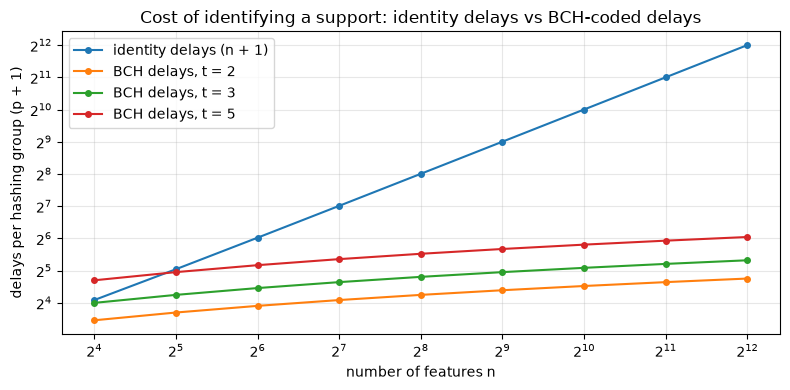

{'identity delays (n + 1)': 1025, 'BCH delays, t = 2': 23, 'BCH delays, t = 3': 34, 'BCH delays, t = 5': 56}


In [28]:
ns = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
delay_costs = {"identity delays (n + 1)": [n + 1 for n in ns]}
for t_ in [2, 3, 5]:
    delay_costs[f"BCH delays, t = {t_}"] = [bch_delay_matrix(n, t_).shape[0] + 1 for n in ns]
utils.plot_delay_cost(ns, delay_costs)
print({name: costs[ns.index(1024)] for name, costs in delay_costs.items()})

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">{'identity delays (n + 1)': 1025, 'BCH delays, t = 2': 23, 'BCH delays, t = 3': 34, 'BCH delays, t = 5': 56}</pre>

</details>

At $n = 1024$, a degree-3 BCH design needs 34 delays where identity delays need 1,025: a 30x saving, and the gap grows linearly with $n$. Notice also the other end of the plot: at
$n = 16$ (our GPT-2 sentence), BCH with $t = 3$ needs 16 delays and identity needs 17. Coding buys nothing for tiny $n$, which is worth remembering when we compare SPEX with other
methods in section 5️⃣.

## Is this bin a singleton?

We now have everything needed to process one bin. Let $D$ be the delay matrix, and let `delays` be $D$ with a zero row stacked on top, so `u = U[:, j]` has $p + 1$ entries with
`u[0]` the zero-delay value. For a candidate support $k$, its **signature** is the vector of signs it would produce, $\sigma_k = \big((-1)^{d_0 \cdot k}, \ldots, (-1)^{d_p \cdot
k}\big)$, with $\sigma_k[0] = 1$.

A real bin can be empty, a singleton, or a collision; and with a real model, every bin also contains a little "noise" from the many tiny coefficients that hash into it. So decoding
a support isn't enough; we have to check it. SPEX's singleton test is:

1. **Decode.** Take the signs of `u[1:] / u[0]` as bits and run `bch_decode`. Skip bins that are (numerically) empty or have `u[0]` ≈ 0.
2. **Check the hash.** A real singleton must sit in the bin it hashes to: `bin_index(M, support) == j`. A collision often decodes to a random support, which fails this check with probability $1 - 2^{-b}$.
3. **Estimate the amplitude** by projecting onto the signature: $\hat F = \sigma_k \cdot u / (p+1)$. This is the least-squares fit of $u \approx F \sigma_k$. It's *signed*: negative coefficients come out negative.
4. **Check the residual.** Accept only if $\| u - \hat F \sigma_k \|^2 \le \gamma \|u\|^2$. The authors use a permissive $\gamma = 0.9$: a bin dominated by one coefficient is accepted, and the leftover will be cleaned up by peeling.

**Soft decoding.** With noisy bins, the sign of a ratio near zero is unreliable, and one wrong bit makes the hard decoder fail. SPEX therefore uses a **Chase decoder**: also try
flipping the least reliable bits (the ratios closest to zero), decode each variant, and keep the candidate whose signature fits best. We'll implement a simple version: with
`chase_depth = c`, take the $c$ bits with the smallest $|u_d / u_0|$, and try flipping none of them, each one, and each pair. Among the candidates that pass step 2, keep the one
with the smallest residual, then apply step 4 to it.

### Exercise - implement `detect_singleton`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20 minutes on this exercise.
> ```

Implement `detect_singleton(u, M, delays, j, t, gamma, chase_depth)`, following the four steps and the soft decoding scheme above. Return `(support, amplitude)` for an accepted
singleton and `None` otherwise. Treat a bin as empty if its energy $\|u\|^2$ is below `1e-20`, and reject it if $|u_0| < 10^{-9}\|u\|$ (ratios are meaningless then).

In [29]:
def detect_singleton(
    u: Float[np.ndarray, " P"],
    M: Int[np.ndarray, "n b"],
    delays: Int[np.ndarray, "P n"],
    j: int,
    t: int,
    gamma: float = 0.9,
    chase_depth: int = 0,
) -> tuple[tuple[int, ...], float] | None:
    """Tests whether bin j (values u across delays) holds a single coefficient; returns (support, amplitude) or None."""
    n = delays.shape[1]
    energy = (u**2).sum()
    if energy < 1e-20 or abs(u[0]) < 1e-9 * np.sqrt(energy):
        return None
    ratios = u[1:] / u[0]
    bits = (ratios < 0).astype(np.int64)
    flips = [()]
    if chase_depth > 0:
        weak = np.argsort(np.abs(ratios))[:chase_depth]
        flips += [(w,) for w in weak] + list(itertools.combinations(weak, 2))
    best = None
    for flip in flips:
        trial = bits.copy()
        trial[list(flip)] ^= 1
        support = bch_decode(trial, n, t)
        if support is None or bin_index(M, support) != j:
            continue
        signature = 1.0 - 2.0 * (delays[:, list(support)].sum(1) % 2)
        amplitude = signature @ u / len(u)
        residual = ((u - amplitude * signature) ** 2).sum() / energy
        if best is None or residual < best[0]:
            best = (residual, support, amplitude)
    if best is None or best[0] > gamma:
        return None
    return best[1], float(best[2])


tests.test_detect_singleton(detect_singleton, bch_delay_matrix)

All tests in `test_detect_singleton` passed!


<details>
<summary>Hint - computing a signature</summary>

`delays[:, list(support)].sum(1) % 2` is $d_p \cdot k$ for every delay $p$ (it's 0 for the zero delay). Then `signature = 1 - 2 * (...)`.
</details>

<details>
<summary>Help - why is the amplitude just a dot product?</summary>

Every signature entry is $\pm 1$, so $\|\sigma_k\|^2 = p + 1$ and the least-squares solution of $\min_F \|u - F\sigma_k\|^2$ is $\sigma_k \cdot u / (p+1)$. If the bin really is a
clean singleton with coefficient $F$, then $u = F\sigma_k$ exactly and this returns $F$, with the right sign.
</details>

## Peeling

One hash isn't enough: in the figure above, 28 of the 41 coefficients sat in collisions. SPEX uses $C = 3$ independent random hashes $M_1, M_2, M_3$, each with the same delays, so
the total number of queries is

$$
Q = C \cdot (p + 1) \cdot 2^b .
$$

Then it **peels**: sweep over all bins of all hashes; whenever a bin passes the singleton test with $(k, \hat F)$, add $\hat F$ to our estimate of $F(k)$, and subtract $\hat F
\sigma_k$ from the bin $k$ hashes to in *every* hash, including bins we haven't looked at yet. A coefficient that collided with $k$ somewhere else is now alone there, and will be
found on a later visit. Repeat sweeps until a sweep finds nothing.

This is the same algorithm as decoding fountain codes or finding the 2-core of a random hypergraph, and it has a sharp threshold: when the number of coefficients per bin $s / 2^b$
is below a constant, peeling resolves everything with high probability; above it, it gets stuck almost immediately. We'll see the threshold in a moment.

### Exercise - implement `spex`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-25 minutes on this exercise.
> ```

Implement the full algorithm:

1. Build the delays: a zero row stacked on `bch_delay_matrix(n, t)`.
2. With `rng = np.random.default_rng(seed)`, draw `n_groups` random matrices `M` of shape `(n, b)` with entries in $\{0, 1\}$, in order.
3. For each, call `aliased_bins` once; stack the bins into an array `U` of shape `(n_groups, P, 2**b)`, and keep all queried masks.
4. Peel: for up to `max_sweeps` sweeps, loop over groups `c` and bins `j`; call `detect_singleton(U[c, :, j], ...)`; on success, add the amplitude to `spectrum[support]` and subtract `amplitude * signature` from `U[c2, :, bin_index(M_c2, support)]` for every group `c2`. Stop after a sweep in which nothing was found.
5. Return the spectrum and the `(Q, n)` array of all masks queried.

If the optional argument `trace` is a list, append `U.copy()` to it before the first sweep and after every sweep (we use this to plot the peeling process).

In [30]:
def spex(
    f: Callable[[np.ndarray], np.ndarray],
    n: int,
    b: int,
    t: int,
    n_groups: int = 3,
    gamma: float = 0.9,
    chase_depth: int = 0,
    max_sweeps: int = 20,
    seed: int = 0,
    trace: list | None = None,
) -> tuple[Spectrum, Int[np.ndarray, "Q n"]]:
    """SPEX: recovers a sparse, degree-<=t Fourier spectrum of f from n_groups * (m t + 1) * 2^b queries."""
    rng = np.random.default_rng(seed)
    delays = np.concatenate([np.zeros((1, n), dtype=np.int64), bch_delay_matrix(n, t)])
    Ms = [rng.integers(0, 2, size=(n, b)) for _ in range(n_groups)]
    U, queried = [], []
    for M in Ms:
        U_c, masks = aliased_bins(f, M, delays)
        U.append(U_c)
        queried.append(masks.reshape(-1, n))
    U = np.stack(U)
    if trace is not None:
        trace.append(U.copy())

    spectrum = {}
    for _ in range(max_sweeps):
        found = 0
        for c, M in enumerate(Ms):
            for j in range(2**b):
                hit = detect_singleton(U[c, :, j], M, delays, j, t, gamma, chase_depth)
                if hit is None:
                    continue
                support, amplitude = hit
                spectrum[support] = spectrum.get(support, 0.0) + amplitude
                signature = 1.0 - 2.0 * (delays[:, list(support)].sum(1) % 2)
                for c2, M2 in enumerate(Ms):
                    U[c2, :, bin_index(M2, support)] -= amplitude * signature
                found += 1
        if trace is not None:
            trace.append(U.copy())
        if found == 0:
            break
    return spectrum, np.concatenate(queried)


tests.test_spex(spex)

All tests in `test_spex` passed!


<details>
<summary>Hint</summary>

The structure is two nested loops inside a sweep loop. Keep a counter of how many singletons were found in the current sweep, and `break` when it's zero. The subtraction must
happen *immediately* (not at the end of the sweep), so that later bins in the same sweep already see the cleaned-up residual.
</details>

<details>
<summary>Help - my recovered coefficients are twice / half the right size</summary>

Check that you subtract the coefficient's signature from its bin in *every* group, including the group where you found it. If you forget the current group, the same bin will be
detected again on the next sweep and its amplitude added twice.
</details>

One more small piece before the experiments: a faithfulness metric.

### Exercise - implement `faithfulness_r2`

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Return the $R^2$ of a spectrum's predictions on a set of masks: $1 - \sum (y - \hat y)^2 / \sum (y - \bar y)^2$. This is the one number we'll use to judge every explanation. Note
that $R^2$ can be negative: an explanation can be worse than predicting the mean.

In [31]:
def faithfulness_r2(spectrum: Spectrum, masks: Int[np.ndarray, "batch n"], values: Float[np.ndarray, " batch"]) -> float:
    """R^2 of the spectrum's predictions against the true values on the given masks."""
    values = np.asarray(values, dtype=np.float64)
    pred = predict_spectrum(spectrum, masks)
    return float(1 - ((values - pred) ** 2).sum() / ((values - values.mean()) ** 2).sum())


tests.test_faithfulness_r2(faithfulness_r2)

All tests in `test_faithfulness_r2` passed!


## Watching collisions dissolve

Let's run SPEX on the planted game from before ($n = 100$, 40 coefficients of degree $\le 3$) with $b = 4$: just 16 bins per hash, so 48 bins in total for 41 coefficients. Every
hash is full of collisions. The heatmap shows the residual energy of every bin, before peeling and after each sweep.

1056 queries (1012 distinct masks), 9 sweeps
true coefficients found: 41/41, spurious: 0, max |error| = 1.4e-11, held-out R² = 1.0000


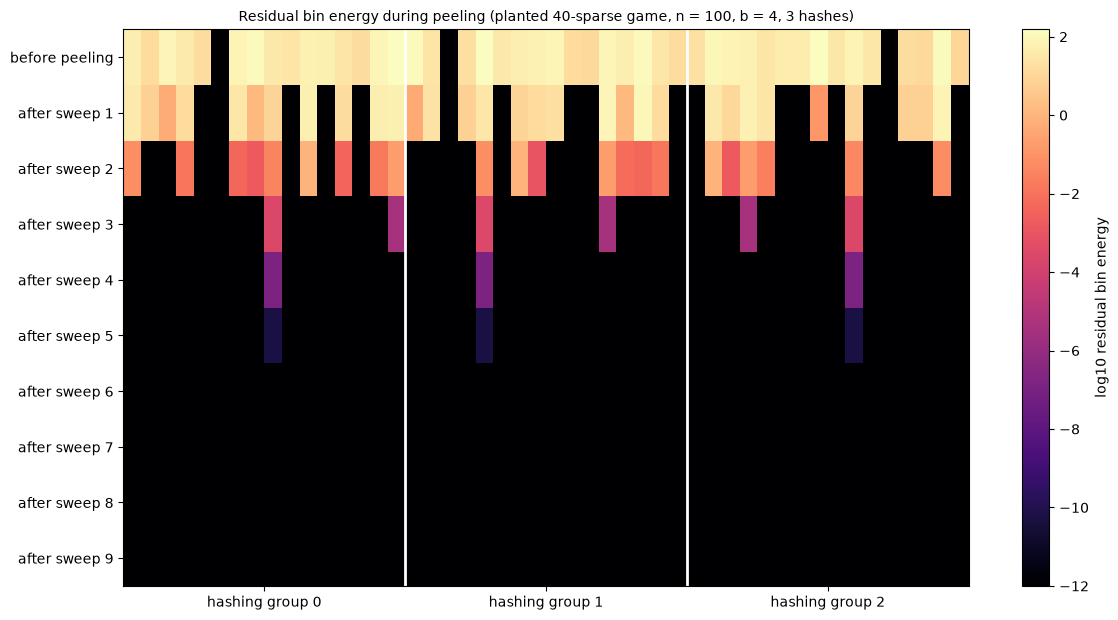

In [32]:
peel_trace = []
recovered, queried = spex(f_planted, n=100, b=4, t=3, seed=0, trace=peel_trace)
held_out = np.random.default_rng(123).integers(0, 2, size=(2000, 100))
y_held_out = f_planted(held_out)

found = {S for S, v in recovered.items() if abs(v) > 1e-8}
max_error = max(abs(recovered.get(S, 0.0) - v) for S, v in planted.items())
print(f"{len(queried)} queries ({len(np.unique(mask_index(queried)))} distinct masks), {len(peel_trace) - 1} sweeps")
print(f"true coefficients found: {len(found & set(planted))}/{len(planted)}, spurious: {len(found - set(planted))}, "
      f"max |error| = {max_error:.1e}, held-out R² = {faithfulness_r2(recovered, held_out, y_held_out):.4f}")
utils.plot_peeling_trace(peel_trace, "Residual bin energy during peeling (planted 40-sparse game, n = 100, b = 4, 3 hashes)")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">1056 queries (1012 distinct masks), 9 sweeps
true coefficients found: 41/41, spurious: 0, max |error| = 1.4e-11, held-out R² = 1.0000</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Each row is a snapshot of all 48 bins (3 hashes × 16 bins); black means numerically zero.

- **Before peeling**, nearly every bin is lit: 41 coefficients in 48 bins means most bins are collisions.
- **Sweep 1** decodes the bins that happen to be singletons (or are dominated by one coefficient) and subtracts each coefficient from its bin in *all three* hashes. Many bins go dark, including some that were collisions in their own hash: their partner was found elsewhere.
- **Sweeps 2-3** clear almost everything that remains, as each subtraction turns more collisions into singletons.
- The few cells still glowing in sweeps 3-5, at energies from $10^{-2}$ down to $10^{-10}$, are *corrections*. With $\gamma = 0.9$, a bin dominated by one coefficient is accepted even though a smaller one shares it, so the first amplitude estimate is slightly off; later sweeps see the leftover and refine it. After that the sweeps only polish at the level of floating-point noise, and sweep 9 finds nothing and stops.

The result: all 41 coefficients, signs included, to 11 decimal places, from 1,056 queries (1,012 distinct masks: a few masks, like the empty one, appear in every hash). For
comparison, there are about 167,000 candidate supports of degree $\le 3$ on 100 features.
</details>

## How many queries does SPEX need?

Now the main SPEX experiment. We vary the number of bins $2^b$ for planted games with $s = 10$, 40 and 160 coefficients ($n = 100$, degree $\le 3$), averaging over three random
designs, and measure $R^2$ on 2,000 held-out random masks. Two **controls** should fail:

- **Dense spectrum**: 3,000 small coefficients instead of a few large ones. Same kind of function, but not sparse.
- **Wrong degree**: 20 coefficients of degree 5, decoded with $t = 3$. Sparse, but outside the code's correction radius.

Before running: where do you expect the $s = 160$ curve to jump? (Hint: compare $s$ with $2^b$.)

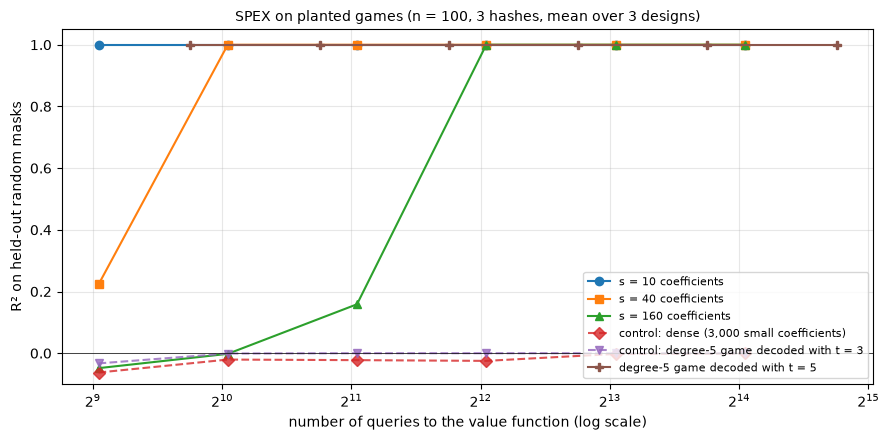

queries at b = 3..8:  t = 3: [528, 1056, 2112, 4224, 8448, 16896]   t = 5: [864, 1728, 3456, 6912, 13824, 27648]
                                             b=3    b=4    b=5    b=6    b=7    b=8
s = 10 coefficients                        1.000  1.000  1.000  1.000  1.000  1.000
s = 40 coefficients                        0.223  1.000  1.000  1.000  1.000  1.000
s = 160 coefficients                      -0.048 -0.002  0.159  1.000  1.000  1.000
control: dense (3,000 small coefficients) -0.063 -0.021 -0.022 -0.025 -0.002 -0.001
control: degree-5 game decoded with t = 3 -0.033 -0.001 -0.000 -0.000 -0.000 -0.000
degree-5 game decoded with t = 5           1.000  1.000  1.000  1.000  1.000  1.000


In [33]:
def spex_budget_curve(spectrum: Spectrum, n: int, t: int, bs: list[int], seeds=(0, 1, 2)) -> tuple[list[int], list[float]]:
    f = spectrum_oracle(spectrum)
    test = np.random.default_rng(123).integers(0, 2, size=(2000, n))
    y = f(test)
    queries, r2s = [], []
    for b in bs:
        results = [spex(f, n, b, t, seed=seed) for seed in seeds]
        queries.append(len(results[0][1]))
        r2s.append(float(np.mean([faithfulness_r2(spec, test, y) for spec, _ in results])))
    return queries, r2s


bs = [3, 4, 5, 6, 7, 8]
curves = {}
for s in [10, 40, 160]:
    curves[f"s = {s} coefficients"] = spex_budget_curve(utils.make_sparse_game(100, s, [1, 2, 3], seed=s), 100, 3, bs)
curves["control: dense (3,000 small coefficients)"] = spex_budget_curve(
    utils.make_sparse_game(100, 3000, [1, 2, 3], seed=7, amplitude=(0.05, 0.15)), 100, 3, bs
)
curves["control: degree-5 game decoded with t = 3"] = spex_budget_curve(utils.make_sparse_game(100, 20, [5], seed=8), 100, 3, bs)
curves["degree-5 game decoded with t = 5"] = spex_budget_curve(utils.make_sparse_game(100, 20, [5], seed=8), 100, 5, bs)

utils.plot_recovery_curves(
    curves,
    "SPEX on planted games (n = 100, 3 hashes, mean over 3 designs)",
    controls=("control: dense (3,000 small coefficients)", "control: degree-5 game decoded with t = 3"),
)
recovery_table = pd.DataFrame({name: dict(zip([f"b={b}" for b in bs], r2)) for name, (_, r2) in curves.items()}).T
print("queries at b = 3..8:  t = 3:", curves["s = 10 coefficients"][0], "  t = 5:", curves["degree-5 game decoded with t = 5"][0])
print(recovery_table.round(3).to_string())

<details>
<summary>Expected output (table)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">queries at b = 3..8:  t = 3: [528, 1056, 2112, 4224, 8448, 16896]   t = 5: [864, 1728, 3456, 6912, 13824, 27648]
                                             b=3    b=4    b=5    b=6    b=7    b=8
s = 10 coefficients                        1.000  1.000  1.000  1.000  1.000  1.000
s = 40 coefficients                        0.223  1.000  1.000  1.000  1.000  1.000
s = 160 coefficients                      -0.048 -0.002  0.159  1.000  1.000  1.000
control: dense (3,000 small coefficients) -0.063 -0.021 -0.022 -0.025 -0.002 -0.001
control: degree-5 game decoded with t = 3 -0.033 -0.001 -0.000 -0.000 -0.000 -0.000
degree-5 game decoded with t = 5           1.000  1.000  1.000  1.000  1.000  1.000</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

**A sharp threshold in the number of bins.** Each sparse game goes from useless to *exact* recovery within one or two doublings of the number of bins: $s = 40$ needs $2^b = 16$
bins per hash (48 bins in total for 41 coefficients), $s = 160$ needs 64 (192 bins for 161 coefficients). Below the threshold peeling stalls almost immediately and $R^2$ is near
zero; above it, every coefficient is found exactly. A rule of thumb from these runs: three hashes with at least as many bins in total as there are coefficients. So the cost grows
with $s$ (and with $t \log n$ through the delays), and not at all with $2^n$.

**The controls fail, as they should.** The dense game never gets above $R^2 = 0$, even with 16,896 queries: its 3,000 coefficients fill every bin with a sum of many terms, nothing
ever looks like a singleton, and SPEX returns (almost) nothing. The degree-5 game decoded with $t = 3$ also stays at zero at every budget: a weight-5 support is outside the code's
correction radius, so `bch_decode` either fails or returns a wrong support that the hash and residual checks reject. More bins don't help, because the problem isn't collisions. The
*same* game decoded with $t = 5$ is recovered exactly at every budget; the price of the larger $t$ is paid in delays (36 per hash instead of 22), not in bins.

Notice that SPEX fails *safely* on these controls: when its assumptions are wrong it returns a near-empty spectrum with $R^2 \approx 0$, rather than a confident wrong answer.
That's the hash and residual checks doing their job.
</details>

### A thousand features

To make the scaling concrete: here is a planted game on $n = 1000$ features with 100 coefficients of degree $\le 3$. The hypercube has $2^{1000} \approx 10^{301}$ points, and there
are about 166 million candidate supports of degree $\le 3$. Enumerating them, as a regression over all low-order terms would, is already out of reach.

In [34]:
big_game = utils.make_sparse_game(n=1000, s=100, degrees=[1, 2, 3], seed=1000)
start = time.time()
big_recovered, big_queries = spex(spectrum_oracle(big_game), n=1000, b=7, t=3, seed=0)
big_found = {S for S, v in big_recovered.items() if abs(v) > 1e-8}
big_test = np.random.default_rng(1).integers(0, 2, size=(2000, 1000))
print(f"n = 1000: {len(big_queries):,} queries, {time.time() - start:.1f}s")
print(f"found {len(big_found & set(big_game))}/{len(big_game)} true coefficients, {len(big_found - set(big_game))} spurious, "
      f"held-out R² = {faithfulness_r2(big_recovered, big_test, spectrum_oracle(big_game)(big_test)):.4f}")
print(f"candidate supports of degree <= 3: {sum(math.comb(1000, d) for d in range(4)):,}")

n = 1000: 11,904 queries, 0.5s
found 101/101 true coefficients, 0 spurious, held-out R² = 1.0000
candidate supports of degree <= 3: 166,667,501


<details>
<summary>Expected output (timings will vary)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">n = 1000: 11,904 queries, 0.5s
found 101/101 true coefficients, 0 spurious, held-out R² = 1.0000
candidate supports of degree &lt;= 3: 166,667,501</pre>

</details>

That's the promise of SPEX: the query cost depends on $s$, $t$ and only *logarithmically* on $n$. The catch, which the controls above made visible, is that this guarantee is about
functions that are *exactly* sparse and low-degree. A real model is only approximately so. Section 5️⃣ will show what that costs.

## Summary of 3️⃣

- **Aliasing**: querying $f$ on a random $b$-dimensional slice of the hypercube and taking a $2^b$-point Walsh transform hashes every Fourier coefficient into one of $2^b$ bins.
- **Delays** multiply each coefficient by a support-dependent sign. With BCH-coded delays, the sign pattern of a singleton is a syndrome, and the support can be recovered algebraically with $O(t \log n)$ delays.
- **Singleton detection** decodes, checks the hash, estimates a signed amplitude, and checks the residual. Soft (Chase) decoding helps with noisy bins.
- **Peeling** across a few independent hashes resolves collisions, with a sharp threshold around a couple of coefficients per bin.
- On exactly sparse, low-degree games SPEX recovers the spectrum exactly with $C(mt+1)2^b$ queries; it fails, visibly, on dense spectra and when the degree exceeds the code's radius $t$.

# 4️⃣ ProxySPEX: Reading the Spectrum off a Tree Proxy

> ##### Learning Objectives
>
> - Expand a decision tree into Fourier coefficients exactly, and verify the extraction against the tree's own predictions
> - Separate the three sources of error in ProxySPEX: proxy fit, extraction (zero) and truncation/refit
> - Understand the hierarchy assumption behind tree proxies, and construct a function that violates it

## Why a proxy?

SPEX's queries are rigid: $C(mt + 1)2^b$ masks from fixed structured designs, and every one of them is needed to keep the bins clean. When the function is only approximately
sparse, many bins never pass the singleton test and those queries are wasted. Butler et al. (2025) observed that in practice SPEX needs a lot of queries on real LLM tasks, and
proposed a two-stage alternative:

1. Query the model on $Q$ **uniformly random** masks, and fit a cheap **proxy** model to the responses: a gradient-boosted tree ensemble.
2. Compute the proxy's Fourier spectrum **exactly**, keep its largest coefficients, and refit their values on the queried data.

Why trees? Two reasons. First, trees are **cheap to read**: a decision tree is a sum of leaf indicators, each leaf indicator is a product of conditions on a few features, and so
every tree has a small, exactly computable Fourier expansion. Second, trees are good at finding **hierarchical** interactions: if a set of features matters jointly *and* its
subsets also matter on their own (as for an AND), then a greedy split on one feature already reduces the error, and the tree can find the rest of the interaction below that split.
Butler et al. report that LLM interactions are typically hierarchical in this sense. We'll test what happens when they aren't.

So ProxySPEX has three distinct sources of error, which we'll keep separate:

- **proxy error**: the trees don't fit the model perfectly;
- **extraction error**: zero, if we do the algebra right, and we'll check that it is;
- **truncation / refit error**: keeping only the top coefficients, and re-estimating them.

## The Fourier expansion of a tree

Consider an internal node that splits on feature $i$, sending $x_i = 0$ to the left subtree (with function $g_L$) and $x_i = 1$ to the right ($g_R$). The node computes

$$
g(x) = \mathbf{1}[x_i = 0]\, g_L(x) + \mathbf{1}[x_i = 1]\, g_R(x) .
$$

Using $\mathbf{1}[x_i = 0] = \tfrac12(1 + \chi_{\{i\}}(x))$ and $\mathbf{1}[x_i = 1] = \tfrac12(1 - \chi_{\{i\}}(x))$:

$$
g(x) = \frac{g_L(x) + g_R(x)}{2} + \chi_{\{i\}}(x)\,\frac{g_L(x) - g_R(x)}{2} .
$$

So if the subtrees have spectra $G_L$ and $G_R$, the node's spectrum is: for every support $S$ appearing in either subtree,

$$
G(S) \mathrel{+}= \frac{G_L(S) + G_R(S)}{2}, \qquad G(S \,\triangle\, \{i\}) \mathrel{+}= \frac{G_L(S) - G_R(S)}{2},
$$

where $\triangle$ is the symmetric difference, because $\chi_{\{i\}}\chi_S = \chi_{S \triangle \{i\}}$ (if $i \in S$, the two factors of $(-1)^{x_i}$ cancel). A leaf with value $v$
has spectrum $\{\emptyset: v\}$. Recursing from the leaves up gives the whole tree's spectrum, and a tree of depth $d$ has no terms of degree $> d$.

<details>
<summary>Aside - when does S contain i already?</summary>

On binary features a tree never splits twice on the same feature along one path (after the first split, the feature is constant in that subtree, so there's nothing to gain). So in
practice $i \notin S$ for every $S$ in the subtrees, and $S \triangle \{i\} = S \cup \{i\}$. Using the symmetric difference costs nothing and keeps the formula correct in general;
a version using set union would silently be wrong for repeated splits.
</details>

We'll use scikit-learn trees. A fitted `DecisionTreeRegressor` exposes its structure as arrays in `tree.tree_`: for node `v`, `children_left[v]` and `children_right[v]` (both `-1`
for a leaf), `feature[v]` (the split feature), and `value[v]` (the leaf prediction, as an array: use `value[v].ravel()[0]`). With 0/1 features, scikit-learn's thresholds are 0.5,
so the left child is always $x_i = 0$.

### Exercise - implement `tree_to_fourier`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement `tree_to_fourier`, which returns the exact Fourier spectrum of a fitted regression tree, by recursion from the root (node 0). The test checks that `predict_spectrum` of
your spectrum reproduces `tree.predict` on every mask.

In [35]:
def tree_to_fourier(tree: DecisionTreeRegressor, n: int) -> Spectrum:
    """Exact Fourier spectrum of a regression tree fitted on 0/1 features."""
    tr = tree.tree_

    def recurse(node: int) -> Spectrum:
        if tr.children_left[node] == -1:
            return {(): float(tr.value[node].ravel()[0])}
        left, right = recurse(tr.children_left[node]), recurse(tr.children_right[node])
        i = int(tr.feature[node])
        out = {}
        for S in set(left) | set(right):
            g_left, g_right = left.get(S, 0.0), right.get(S, 0.0)
            out[S] = out.get(S, 0.0) + (g_left + g_right) / 2
            S_xor_i = tuple(sorted(set(S) ^ {i}))
            out[S_xor_i] = out.get(S_xor_i, 0.0) + (g_left - g_right) / 2
        return out

    return recurse(0)


tests.test_tree_to_fourier(tree_to_fourier)

All tests in `test_tree_to_fourier` passed!


<details>
<summary>Hint</summary>

Write an inner function `recurse(node)` that returns a dict. For a leaf, return `{(): value}`. For a split node, recurse into both children, then loop over the union of their keys
and apply the two update rules. `tuple(sorted(set(S) ^ {i}))` computes $S \triangle \{i\}$ in canonical form.
</details>

### Exercise - implement `gbt_to_fourier`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

A gradient-boosted ensemble predicts

$$
\hat f(x) = c_0 + \eta \sum_{r=1}^{R} h_r(x) ,
$$

where $c_0$ is the initial constant prediction (the mean of the training targets), $\eta$ is the learning rate and $h_r$ are the trees, each fitted to the residuals of the ensemble
so far. The Fourier transform is linear, so the ensemble's spectrum is $c_0$ on the constant plus $\eta$ times the sum of the trees' spectra.

For a fitted `GradientBoostingRegressor`: the trees are `gbt.estimators_[:, 0]`, the learning rate is `gbt.learning_rate`, and $c_0$ is `gbt.init_.constant_` (an array; take its
single entry).

In [36]:
def gbt_to_fourier(gbt: GradientBoostingRegressor, n: int) -> Spectrum:
    """Exact Fourier spectrum of a fitted scikit-learn gradient-boosted regression ensemble."""
    spectrum = {(): float(np.ravel(gbt.init_.constant_)[0])}
    for tree in gbt.estimators_[:, 0]:
        for S, v in tree_to_fourier(tree, n).items():
            spectrum[S] = spectrum.get(S, 0.0) + gbt.learning_rate * v
    return spectrum


tests.test_gbt_to_fourier(gbt_to_fourier)

All tests in `test_gbt_to_fourier` passed!


## Selecting and refitting

A fitted ensemble of 500 depth-5 trees has a spectrum with thousands of terms, most of them tiny: the trees' fitting noise. ProxySPEX keeps the smallest set of largest-magnitude
coefficients that holds 95% of the (non-constant) energy, and then **refits** the kept coefficients on the queried data by ridge regression on their characters, because the trees'
estimates of individual coefficients are biased by shrinkage and by the noise terms we just dropped.

<details>
<summary>Aside - two details where implementations differ</summary>

- **The boundary coefficient.** The reference implementation (`spectralexplain` 0.0.4) finds the coefficient at the 95% boundary and then keeps coefficients *strictly larger* than it, which drops the boundary coefficient and all ties. On a pure parity game, where the whole spectrum is one coefficient, that keeps nothing and crashes the refit. We keep the boundary coefficient (an inclusive rule).
- **The constant.** The constant is excluded from the energy calculation (it's not an interaction), but it must be kept for the refit, especially since the refit regression has no separate intercept. We always keep it.
- **A cap on the number of terms.** When the proxy has fit mostly noise (for example on shuffled responses, or a dense function), its spectrum has tens of thousands of comparable terms, and 95% of the energy can mean more terms than we have queries. Refitting more coefficients than data points is meaningless (and very slow), so our `proxyspex` keeps at most `budget // 2` terms. The reference implementation has no cap. On the GPT-2 games the cap rarely binds; on the shuffled and dense controls it always does.

None of these choices changes the method's idea; they're worth knowing about if you compare against the reference code (see the bonus section).
</details>

### Exercise - implement `select_and_refit`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

Implement `select_and_refit(spectrum, X, y, energy)`:

1. Sort the non-constant terms by $|F(S)|$, descending. Keep the smallest prefix whose cumulative share of the non-constant energy is at least `energy` (inclusive: if the first $k$ terms reach exactly `energy`, keep $k$). If `max_terms` is given, keep at most that many.
2. Add the constant `()` to the kept supports.
3. Build the `(Q, k+1)` character matrix of the kept supports on the training masks `X`, and fit `RidgeCV(alphas=np.logspace(-6, 2, 30), fit_intercept=False, gcv_mode="svd")` to `y`. (The constant's character is the all-ones column, so it plays the role of the intercept.)
4. Return the spectrum `{support: refitted coefficient}`.

In [37]:
def select_and_refit(
    spectrum: Spectrum,
    X: Int[np.ndarray, "Q n"],
    y: Float[np.ndarray, " Q"],
    energy: float = 0.95,
    max_terms: int | None = None,
) -> Spectrum:
    """
    Keeps the top coefficients holding `energy` of the non-constant energy (at most `max_terms` of them, if given),
    plus the constant, and refits them by ridge regression on (X, y).
    """
    terms = sorted(((S, v) for S, v in spectrum.items() if len(S) > 0), key=lambda kv: -abs(kv[1]))
    energies = np.array([v**2 for _, v in terms])
    cumulative = np.cumsum(energies) / energies.sum()
    k = int(np.searchsorted(cumulative, energy - 1e-12) + 1)
    if max_terms is not None:
        k = min(k, max_terms)
    supports = [()] + [S for S, _ in terms[:k]]
    K = supports_to_matrix(supports, X.shape[1])
    chi = 1.0 - 2.0 * ((X @ K.T) % 2)
    ridge = RidgeCV(alphas=np.logspace(-6, 2, 30), fit_intercept=False, gcv_mode="svd").fit(chi, y)
    return dict(zip(supports, ridge.coef_.tolist()))


tests.test_select_and_refit(select_and_refit)

All tests in `test_select_and_refit` passed!


<details>
<summary>Hint - the inclusive boundary</summary>

With `cumulative = np.cumsum(energies) / energies.sum()`, the number of terms to keep is `np.searchsorted(cumulative, energy) + 1`: `searchsorted` returns the first index whose
value is $\ge$ `energy`. Subtract a tiny tolerance (`energy - 1e-12`) to protect against floating-point error when the boundary is hit exactly.
</details>

### Exercise - assemble `proxyspex`, and a first-order baseline

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `proxyspex(f, n, budget, ...)`:

1. Draw `budget` uniformly random masks with `np.random.default_rng(seed).integers(0, 2, size=(budget, n))` and query `f` once on all of them.
2. Fit `GradientBoostingRegressor(n_estimators=n_estimators, max_depth=max_depth, learning_rate=0.1, random_state=seed)`.
3. Extract its spectrum, then select and refit with `max_terms=budget // 2`. Return the spectrum and the masks.

The paper uses LightGBM with a small cross-validated grid over depth, number of trees and learning rate; we use fixed settings (500 trees of depth 5) to keep things fast and
simple, and you can try tuning them in the bonus.

Also implement `first_order_baseline(X, y)`, our stand-in for first-order attribution methods: fit an ordinary linear regression $y \approx a + \sum_i w_i x_i$ on the same masks,
and return it **as a Fourier spectrum** so that it can be evaluated and compared like everything else. (By Parseval, this least-squares fit on uniform masks converges to the best
possible additive explanation, i.e. it's the *strongest* first-order baseline; it is the Banzhaf-style counterpart of KernelSHAP, which weights masks differently.) Use $x_i =
\tfrac12 - \tfrac12\chi_{\{i\}}$ to convert.

In [38]:
def proxyspex(
    f: Callable[[np.ndarray], np.ndarray],
    n: int,
    budget: int,
    seed: int = 0,
    max_depth: int = 5,
    n_estimators: int = 500,
    energy: float = 0.95,
) -> tuple[Spectrum, Int[np.ndarray, "budget n"]]:
    """ProxySPEX: fit boosted trees to f on `budget` random masks, extract their spectrum, select and refit."""
    X = np.random.default_rng(seed).integers(0, 2, size=(budget, n))
    y = f(X)
    gbt = GradientBoostingRegressor(
        n_estimators=n_estimators, max_depth=max_depth, learning_rate=0.1, random_state=seed
    ).fit(X, y)
    return select_and_refit(gbt_to_fourier(gbt, n), X, y, energy, max_terms=budget // 2), X


def first_order_baseline(X: Int[np.ndarray, "Q n"], y: Float[np.ndarray, " Q"]) -> Spectrum:
    """Least-squares additive model y ~ a + sum_i w_i x_i, returned as a Fourier spectrum."""
    linear = LinearRegression().fit(X, y)
    spectrum = {(): float(linear.intercept_ + linear.coef_.sum() / 2)}
    for i, w in enumerate(linear.coef_):
        spectrum[(i,)] = float(-w / 2)
    return spectrum


tests.test_proxyspex(proxyspex)
tests.test_first_order_baseline(first_order_baseline)

All tests in `test_proxyspex` passed!
All tests in `test_first_order_baseline` passed!


<details>
<summary>Hint - converting the linear model</summary>

$a + \sum_i w_i x_i = a + \sum_i w_i \left(\tfrac12 - \tfrac12\chi_{\{i\}}\right) = \left(a + \tfrac12\sum_i w_i\right) - \sum_i \tfrac{w_i}{2}\chi_{\{i\}}$.
</details>

## Separating the three errors

Let's open ProxySPEX up on two kinds of planted game:

- an **AND game**: 15 random AND terms of degree 1-3, so its Fourier spectrum has a few dozen terms, all hierarchical (every AND of degree $d$ comes with Fourier terms on all of its subsets);
- a **pure parity game**: 5 parities of degree 3 and a constant, and nothing else. Extremely sparse, but no single feature or pair has any marginal effect: there's no lower-order "footprint" for a greedy split to find.

We give ProxySPEX the same budget SPEX uses at $b = 5$, $t = 3$ (1,824 queries for $n = 32$, 2,112 for $n = 100$), and measure on 2,000 held-out masks: how well the fitted trees
predict the game (proxy error), the largest difference between the trees' predictions and their extracted spectrum (extraction error), and how well the final selected and refit
spectrum predicts the game. We also report the explanation's **effective size**: the number of its terms that carry 99% of its (non-constant) energy. The ridge refit can leave many
terms with tiny coefficients, and those shouldn't count.

Before running: which of the three numbers do you expect to be bad for the parity game?

In [39]:
def effective_size(spectrum: Spectrum, fraction: float = 0.99) -> int:
    """Number of non-constant terms (largest first) needed to hold `fraction` of the spectrum's non-constant energy."""
    energies = np.sort([v**2 for S, v in spectrum.items() if S])[::-1]
    if len(energies) == 0 or energies.sum() == 0:
        return 0
    return int(np.searchsorted(np.cumsum(energies) / energies.sum(), fraction - 1e-12) + 1)


def spex_budget(n: int, b: int = 5, t: int = 3, n_groups: int = 3) -> int:
    """Number of queries SPEX makes with these settings."""
    return n_groups * (bch_delay_matrix(n, t).shape[0] + 1) * 2**b

In [40]:
held_out = {n: np.random.default_rng(123).integers(0, 2, size=(2000, n)) for n in [32, 100]}
stage_games = [
    ("AND game", 32, utils.make_and_game(32, 15, [1, 2, 3], seed=1)),
    ("pure parity game", 32, utils.make_sparse_game(32, 5, [3], seed=3)),
    ("pure parity game", 100, utils.make_sparse_game(100, 5, [3], seed=3)),
]
for name, n, game in stage_games:
    f_game = spectrum_oracle(game)
    y_test = f_game(held_out[n])
    budget = spex_budget(n)
    X_train = np.random.default_rng(0).integers(0, 2, size=(budget, n))
    y_train = f_game(X_train)
    gbt = GradientBoostingRegressor(n_estimators=500, max_depth=5, learning_rate=0.1, random_state=0).fit(X_train, y_train)
    full_spectrum = gbt_to_fourier(gbt, n)
    final_spectrum = select_and_refit(full_spectrum, X_train, y_train, max_terms=budget // 2)
    tree_r2 = 1 - ((gbt.predict(held_out[n]) - y_test) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()
    extraction_error = np.abs(gbt.predict(held_out[n]) - predict_spectrum(full_spectrum, held_out[n])).max()
    print(f"{name}, n = {n} ({len(game)} true Fourier terms, {budget} queries)")
    print(f"  1. proxy:      trees' held-out R² = {tree_r2:.3f}")
    print(f"  2. extraction: {len(full_spectrum):,} terms, max |trees - spectrum| = {extraction_error:.1e}")
    print(f"  3. selection:  {len(final_spectrum)} terms kept (effective size {effective_size(final_spectrum)}), "
          f"final held-out R² = {faithfulness_r2(final_spectrum, held_out[n], y_test):.3f}, "
          f"true supports kept: {len(set(final_spectrum) & set(game))}/{len(game)}")

AND game, n = 32 (41 true Fourier terms, 1824 queries)
  1. proxy:      trees' held-out R² = 0.979
  2. extraction: 24,001 terms, max |trees - spectrum| = 2.4e-14
  3. selection:  25 terms kept (effective size 23), final held-out R² = 0.953, true supports kept: 25/41


pure parity game, n = 32 (6 true Fourier terms, 1824 queries)
  1. proxy:      trees' held-out R² = 0.535
  2. extraction: 26,621 terms, max |trees - spectrum| = 1.2e-14
  3. selection:  913 terms kept (effective size 5), final held-out R² = 1.000, true supports kept: 6/6


pure parity game, n = 100 (6 true Fourier terms, 2112 queries)
  1. proxy:      trees' held-out R² = -0.118
  2. extraction: 84,692 terms, max |trees - spectrum| = 9.8e-15
  3. selection:  1057 terms kept (effective size 596), final held-out R² = 0.676, true supports kept: 5/6


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">AND game, n = 32 (41 true Fourier terms, 1824 queries)
  1. proxy:      trees' held-out R² = 0.979
  2. extraction: 24,001 terms, max |trees - spectrum| = 1.3e-13
  3. selection:  25 terms kept (effective size 23), final held-out R² = 0.953, true supports kept: 25/41
pure parity game, n = 32 (6 true Fourier terms, 1824 queries)
  1. proxy:      trees' held-out R² = 0.535
  2. extraction: 26,621 terms, max |trees - spectrum| = 8.7e-14
  3. selection:  913 terms kept (effective size 5), final held-out R² = 1.000, true supports kept: 6/6
pure parity game, n = 100 (6 true Fourier terms, 2112 queries)
  1. proxy:      trees' held-out R² = -0.118
  2. extraction: 84,692 terms, max |trees - spectrum| = 1.1e-13
  3. selection:  1057 terms kept (effective size 596), final held-out R² = 0.676, true supports kept: 5/6</pre>

</details>

**Extraction is exact.** In every case the extracted spectrum (tens of thousands of terms) reproduces the trees to about $10^{-13}$, i.e. floating-point precision. Whatever goes
wrong with ProxySPEX, it isn't step 2.

**AND game.** The trees fit well ($R^2 = 0.98$). Selection keeps 25 terms (including the constant) and the refit reaches 0.95, slightly *below* the trees: the 16 smallest true
terms (a degree-3 AND spreads its weight over eight Fourier terms of magnitude $w/8$) fall under the 95% energy cut. That's the price of a compact explanation.

**Pure parities, $n = 32$.** Exactly as the hierarchy argument predicts, the trees are poor ($R^2 = 0.54$): no single split reduces the error, so the greedy splits are close to
random. And yet the final explanation is *perfect*, with an effective size of 5 (the five parities; the other 908 kept terms end up with negligible coefficients after the refit).
How? The trees' spectrum is a bad *model* but a decent *candidate list*: with 913 slots among only 5,488 possible supports of degree $\le 3$, the true parities made it onto the
list, and the ridge refit, which fits the actual data, picked them out.

**Pure parities, $n = 100$.** With more features there are about 167,000 supports of degree $\le 3$, and the trees have no footprint to follow: their $R^2$ is *negative*. Now the
candidate list misses one of the parities and fills up with noise, and the final explanation has $R^2 = 0.68$ with an effective size of 596. The refit can only rescue the proxy if
the proxy at least proposes the right supports.

## Each method fails where its assumption breaks

Now the controls for both methods at once, at $n = 100$. Four planted games, each method given the same budget of 2,112 queries (SPEX at $b = 5$, $t = 3$):

- **AND game**: 15 random ANDs of degree $\le 3$. Sparse in both bases, and hierarchical. Both methods' assumptions hold.
- **Sparse Fourier game**: 40 random Fourier coefficients of degree $\le 3$. Exactly SPEX's model. Not hierarchical: an interaction $\{3, 17\}$ need not come with terms on $\{3\}$ or $\{17\}$.
- **Pure parities** (as above): no lower-order footprint at all.
- **Dense game**: 3,000 small random coefficients. Nobody's assumption holds.

We also run ProxySPEX on **shuffled responses** (the same masks, with the values permuted), which should fail on every game, and the first-order baseline. The right-hand panel
shows each explanation's effective size against the true number of terms.

  0%|          | 0/4 [00:00<?, ?it/s]

budget per method: 2112 queries


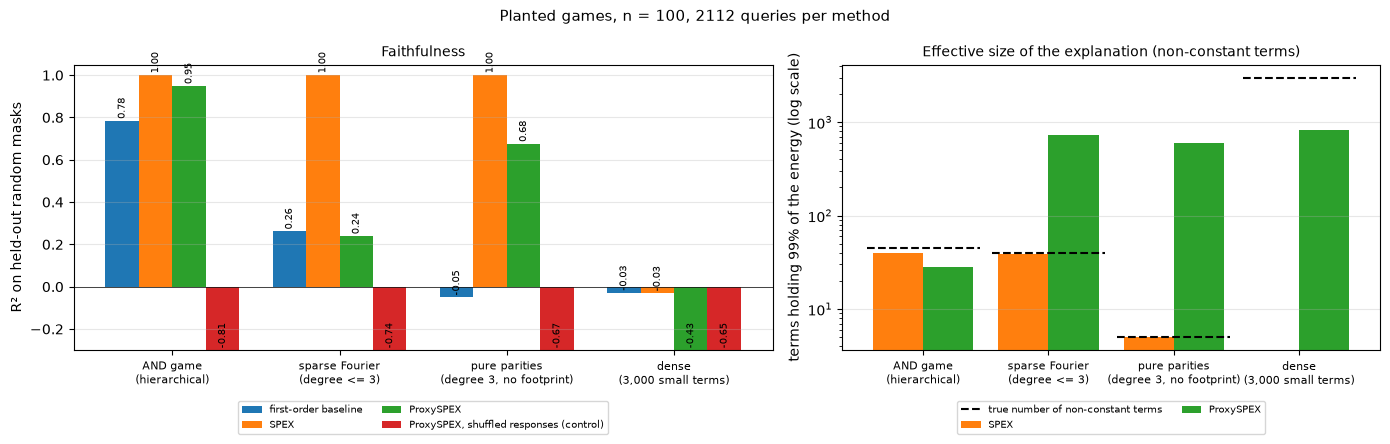

                                        first-order baseline   SPEX  ProxySPEX  ProxySPEX, shuffled responses (control)  SPEX eff. size  ProxySPEX eff. size  true terms
AND game (hierarchical)                                0.784  1.000      0.949                                   -0.812              40                   28          45
sparse Fourier (degree <= 3)                           0.262  1.000      0.239                                   -0.742              39                  726          40
pure parities (degree 3, no footprint)                -0.051  1.000      0.676                                   -0.670               5                  596           5
dense (3,000 small terms)                             -0.028 -0.031     -0.429                                   -0.650               0                  830        3000


In [41]:
n_cmp = 100
planted_games = {
    "AND game\n(hierarchical)": utils.make_and_game(n_cmp, 15, [1, 2, 3], seed=1),
    "sparse Fourier\n(degree <= 3)": utils.make_sparse_game(n_cmp, 40, [1, 2, 3], seed=2),
    "pure parities\n(degree 3, no footprint)": utils.make_sparse_game(n_cmp, 5, [3], seed=3),
    "dense\n(3,000 small terms)": utils.make_sparse_game(n_cmp, 3000, [1, 2, 3], seed=4, amplitude=(0.05, 0.15)),
}
method_results, method_sizes = {}, {}
for name, game in tqdm(planted_games.items()):
    f_game = spectrum_oracle(game)
    y_test = f_game(held_out[n_cmp])
    spex_spectrum, spex_queries = spex(f_game, n_cmp, b=5, t=3, seed=0)
    budget = len(spex_queries)
    proxy_spectrum, X_proxy = proxyspex(f_game, n_cmp, budget, seed=0)
    shuffle_rng = np.random.default_rng(1)
    shuffled_spectrum, _ = proxyspex(lambda X: shuffle_rng.permutation(f_game(X)), n_cmp, budget, seed=0)
    first_order = first_order_baseline(X_proxy, f_game(X_proxy))
    method_results[name] = {
        "first-order baseline": faithfulness_r2(first_order, held_out[n_cmp], y_test),
        "SPEX": faithfulness_r2(spex_spectrum, held_out[n_cmp], y_test),
        "ProxySPEX": faithfulness_r2(proxy_spectrum, held_out[n_cmp], y_test),
        "ProxySPEX, shuffled responses (control)": faithfulness_r2(shuffled_spectrum, held_out[n_cmp], y_test),
    }
    method_sizes[name] = {"SPEX": effective_size(spex_spectrum), "ProxySPEX": effective_size(proxy_spectrum)}
print(f"budget per method: {budget} queries")
utils.plot_method_comparison(
    method_results,
    method_sizes,
    {name: len(game) - 1 for name, game in planted_games.items()},
    f"Planted games, n = {n_cmp}, {budget} queries per method",
)
table = pd.DataFrame(method_results).T.round(3)
table["SPEX eff. size"] = [method_sizes[g]["SPEX"] for g in planted_games]
table["ProxySPEX eff. size"] = [method_sizes[g]["ProxySPEX"] for g in planted_games]
table["true terms"] = [len(g) - 1 for g in planted_games.values()]
print(table.rename(index=lambda s: s.replace("\n", " ")).to_string())

<details>
<summary>Expected output (table)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">budget per method: 2112 queries
                                        first-order baseline   SPEX  ProxySPEX  ProxySPEX, shuffled responses (control)  SPEX eff. size  ProxySPEX eff. size  true terms
AND game (hierarchical)                                0.784  1.000      0.949                                   -0.812              40                   28          45
sparse Fourier (degree &lt;= 3)                           0.262  1.000      0.239                                   -0.742              39                  726          40
pure parities (degree 3, no footprint)                -0.051  1.000      0.676                                   -0.670               5                  596           5
dense (3,000 small terms)                             -0.028 -0.031     -0.429                                   -0.650               0                  830        3000</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Read the figure one game at a time.

- **AND game.** Both assumptions hold, and both methods work: SPEX recovers it exactly (its effective size, 40, is just below the true 45 because the smallest terms carry under 1% of the energy); ProxySPEX gets 0.95 with 28 effective terms. The first-order baseline does surprisingly well (0.78), because low-order ANDs have large first-order footprints, and that footprint is exactly what lets the trees find them.
- **Sparse Fourier game.** SPEX: exact. ProxySPEX: $R^2 = 0.24$, *below the first-order baseline*, with an effective size of 726. These interactions have no reason to come with lower-order terms on the same features, so the trees can't find them, and the refit spreads the weight over hundreds of wrong candidates.
- **Pure parities.** SPEX: exact, 5 terms. ProxySPEX: 0.68 with 596 effective terms, as in the previous cell. The first-order baseline is at zero, which is correct: parities have no first-order component at all.
- **Dense game.** Everything fails. SPEX returns an empty spectrum ($R^2 = -0.03$), ProxySPEX overfits ($-0.43$), and the first-order baseline is at zero.
- **Shuffled responses.** ProxySPEX trained on permuted values is far worse than predicting the mean on every game ($-0.65$ to $-0.81$). An explanation with hundreds of terms will happily fit noise; only held-out faithfulness exposes it.

So the two methods make different bets. SPEX bets on *exact sparsity and low degree*: when that holds it is exact, whatever the interactions look like, and when it fails it returns
(almost) nothing. ProxySPEX bets on *hierarchy*: when that holds it works, and when it fails it returns a large explanation that isn't faithful. Which bet suits real models is an
empirical question, and the subject of the next section.
</details>

## Summary of 4️⃣

- Every decision tree has an exact Fourier expansion, with terms of degree at most its depth, computed by one recursion; an ensemble's spectrum is the learning-rate-weighted sum. Extraction is exact to floating-point precision.
- ProxySPEX = random queries + boosted trees + exact extraction + energy-based selection + ridge refit. Its errors come from the proxy fit and the selection, never from the extraction.
- Trees find interactions greedily, so ProxySPEX relies on interactions leaving lower-order footprints (hierarchy). It works on AND games; on pure parities and on random sparse Fourier games at $n = 100$ its trees fail and its explanations are large and unfaithful ($R^2$ of 0.68 and 0.24).
- At small $n$ the refit can rescue a bad proxy, if the proxy's candidate list happens to contain the true supports.
- SPEX recovers every exactly sparse, low-degree game exactly, hierarchical or not, and returns (almost) nothing when the spectrum is dense or the degree exceeds $t$.
- Shuffled responses produce ProxySPEX explanations that are far worse than predicting the mean.

# 5️⃣ Head-to-Head on GPT-2

> ##### Learning Objectives
>
> - Compare interaction-discovery methods by faithfulness per query, against exact ceilings and shuffled controls
> - Check that discovered interactions are specific, not just "more parameters", with a permuted-support control
> - Read pairwise Shapley interactions on a real model and connect them to a known circuit
> - Run the methods live on your own prompt

## Faithfulness against the exact game

Back to GPT-2. Because we evaluated all 65,536 masks in section 2️⃣, we can give the methods a *lookup table* as their value function: querying the table is identical to querying
the model (it's deterministic), but costs nothing, so we can try many budgets. And we can measure each explanation's $R^2$ on **all** $2^{16}$ masks, which is its exact
faithfulness under uniform masking.

For both read-outs we run:

- **SPEX** with $t = 3$, Chase depth 3, and $b = 4, \ldots, 8$ ($Q = 768$ to 12,288 queries);
- **ProxySPEX** with $Q = 256$ to 4,096 random masks;
- the **first-order baseline** on the same masks as ProxySPEX;
- **ProxySPEX on shuffled responses**, a control that should fail;

and draw two exact ceilings from the spectrum: the best possible additive explanation (degree-1 energy) and the best possible explanation using only terms of degree $\le 3$ (which
is all SPEX with $t = 3$ is allowed to find).

This takes about a minute.

SPEX, logit diff:   0%|          | 0/5 [00:00<?, ?it/s]

ProxySPEX, logit diff:   0%|          | 0/5 [00:00<?, ?it/s]

SPEX, p(Mary):   0%|          | 0/5 [00:00<?, ?it/s]

ProxySPEX, p(Mary):   0%|          | 0/5 [00:00<?, ?it/s]

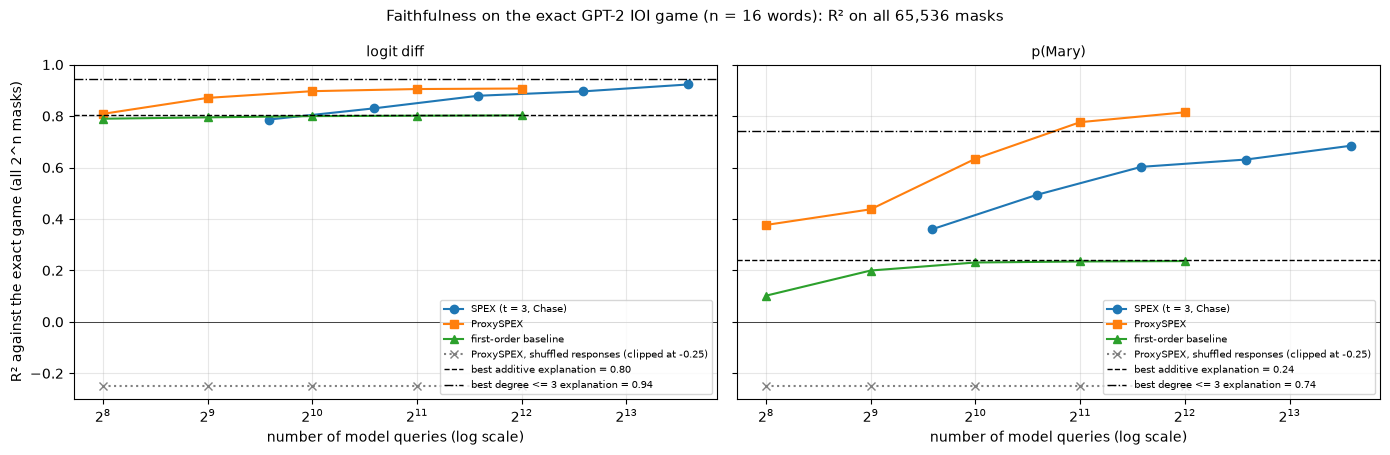

logit diff
  SPEX (t = 3, Chase)             Q=768: +0.786  Q=1536: +0.830  Q=3072: +0.879  Q=6144: +0.896  Q=12288: +0.923
  ProxySPEX                       Q=256: +0.808  Q=512: +0.871  Q=1024: +0.897  Q=2048: +0.905  Q=4096: +0.907
  first-order baseline            Q=256: +0.790  Q=512: +0.795  Q=1024: +0.800  Q=2048: +0.801  Q=4096: +0.803
  ProxySPEX, shuffled responses   Q=256: -0.387  Q=512: -0.529  Q=1024: -0.849  Q=2048: -0.901  Q=4096: -0.509
p(Mary)
  SPEX (t = 3, Chase)             Q=768: +0.360  Q=1536: +0.494  Q=3072: +0.603  Q=6144: +0.631  Q=12288: +0.685
  ProxySPEX                       Q=256: +0.377  Q=512: +0.438  Q=1024: +0.634  Q=2048: +0.776  Q=4096: +0.815
  first-order baseline            Q=256: +0.102  Q=512: +0.200  Q=1024: +0.231  Q=2048: +0.235  Q=4096: +0.236
  ProxySPEX, shuffled responses   Q=256: -0.657  Q=512: -0.639  Q=1024: -0.822  Q=2048: -0.844  Q=4096: -0.676


In [42]:
def lookup_value_function(values: np.ndarray) -> Callable[[np.ndarray], np.ndarray]:
    return lambda masks: values[mask_index(masks)]


spex_bs = [4, 5, 6, 7, 8]
proxy_budgets = [256, 512, 1024, 2048, 4096]
head_to_head, ioi_spectra = {}, {}
for name, values in exact_values.items():
    f_ioi = lookup_value_function(values)
    spex_runs = [spex(f_ioi, n_words, b, t=3, chase_depth=3, seed=0) for b in tqdm(spex_bs, desc=f"SPEX, {name}")]
    proxy_runs = [proxyspex(f_ioi, n_words, budget, seed=0) for budget in tqdm(proxy_budgets, desc=f"ProxySPEX, {name}")]
    shuffle_rng = np.random.default_rng(1)
    shuffled_runs = [proxyspex(lambda X: shuffle_rng.permutation(f_ioi(X)), n_words, budget, seed=0) for budget in proxy_budgets]
    first_order_runs = [first_order_baseline(X, f_ioi(X)) for _, X in proxy_runs]

    r2 = lambda spectrum: faithfulness_r2(spectrum, X_all, values)  # noqa: E731
    de = degree_energy(exact_F[name])
    head_to_head[name] = {
        "curves": {
            "SPEX (t = 3, Chase)": ([len(X) for _, X in spex_runs], [r2(s) for s, _ in spex_runs]),
            "ProxySPEX": (proxy_budgets, [r2(s) for s, _ in proxy_runs]),
            "first-order baseline": (proxy_budgets, [r2(s) for s in first_order_runs]),
        },
        "controls": {"ProxySPEX, shuffled responses": (proxy_budgets, [r2(s) for s, _ in shuffled_runs])},
        "hlines": {"best additive explanation": de[0], "best degree <= 3 explanation": de[:3].sum()},
    }
    ioi_spectra[name] = {"SPEX": spex_runs, "ProxySPEX": proxy_runs}

utils.plot_head_to_head(head_to_head, "Faithfulness on the exact GPT-2 IOI game (n = 16 words): R² on all 65,536 masks")
for name, panel in head_to_head.items():
    print(name)
    for method, (q, r2s) in {**panel["curves"], **panel["controls"]}.items():
        print(f"  {method:<32}" + "  ".join(f"Q={qq}: {rr:+.3f}" for qq, rr in zip(q, r2s)))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">logit diff
  SPEX (t = 3, Chase)             Q=768: +0.786  Q=1536: +0.830  Q=3072: +0.879  Q=6144: +0.896  Q=12288: +0.923
  ProxySPEX                       Q=256: +0.808  Q=512: +0.871  Q=1024: +0.897  Q=2048: +0.905  Q=4096: +0.907
  first-order baseline            Q=256: +0.790  Q=512: +0.795  Q=1024: +0.800  Q=2048: +0.801  Q=4096: +0.803
  ProxySPEX, shuffled responses   Q=256: -0.384  Q=512: -0.524  Q=1024: -0.849  Q=2048: -0.901  Q=4096: -0.509
p(Mary)
  SPEX (t = 3, Chase)             Q=768: +0.360  Q=1536: +0.494  Q=3072: +0.603  Q=6144: +0.631  Q=12288: +0.685
  ProxySPEX                       Q=256: +0.379  Q=512: +0.437  Q=1024: +0.634  Q=2048: +0.776  Q=4096: +0.815
  first-order baseline            Q=256: +0.102  Q=512: +0.200  Q=1024: +0.231  Q=2048: +0.235  Q=4096: +0.236
  ProxySPEX, shuffled responses   Q=256: -0.657  Q=512: -0.639  Q=1024: -0.822  Q=2048: -0.844  Q=4096: -0.676</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

**Interactions buy real faithfulness, and how much depends on the read-out.** On `p(Mary)`, the first-order baseline saturates at its ceiling of 0.24 almost immediately, while
ProxySPEX reaches 0.78 with 2,048 queries (3% of the cube) and 0.82 with 4,096. On the logit difference, where 80% of the variance is additive, interactions take $R^2$ from 0.80 to
0.91 (ProxySPEX) and 0.92 (SPEX at 12,288 queries): they recover a bit over half of the variance that no additive explanation can reach.

**ProxySPEX is much more query-efficient than SPEX here.** At around 3,000 queries, ProxySPEX's `p(Mary)` explanation (0.78 at 2,048) beats SPEX's (0.60 at 3,072), and SPEX needs
12,288 queries, 19% of the entire cube, to reach 0.69. This matches what Butler et al. report on LLM tasks. Two reasons are visible in this notebook: at $n = 16$ the BCH code saves
nothing (16 delays per hash against 17 for identity delays), and a real model's spectrum has a long tail of small coefficients that pollutes every bin, so many bins fail the
singleton test and their queries are wasted. ProxySPEX's random queries are never wasted.

**But SPEX doesn't plateau.** On the logit difference, ProxySPEX levels off around 0.91: the 95%-energy rule keeps only 60-odd terms, and more queries don't change that. SPEX keeps
improving as bins are added and ends up slightly ahead. On `p(Mary)`, ProxySPEX goes *above* the dash-dot "best degree $\le 3$" line (0.82 > 0.74): its depth-5 trees can represent
terms up to degree 5, which matter for this AND-like read-out. SPEX with $t = 3$ is capped by that line by construction.

**Controls.** ProxySPEX trained on shuffled responses is far below zero at every budget ($-0.38$ to $-0.90$; the plot clips these at $-0.25$). The explanations' faithfulness comes
from the model's actual structure, not from the flexibility of a few hundred fitted coefficients.
</details>

### What about the Shapley values themselves?

Our first-order baseline is the *best-fitting* additive model, which is a generous comparison. The additive explanation people usually look at is different: KernelSHAP (as in
[16.2]) estimates Shapley values $\phi_i$ and presents $f(\emptyset) + \sum_i \phi_i x_i$ as the explanation model, which by efficiency matches the model exactly on the empty and
full masks. How faithful is that explanation on the masks in between? We can compute the exact Shapley values from the exact Möbius coefficients and check.

In [43]:
for name, values in exact_values.items():
    phi = shapley_interactions(array_to_spectrum(mobius_transform(values)), max_order=1)
    phi = np.array([phi.get((i,), 0.0) for i in range(n_words)])
    shapley_model = values[0] + X_all @ phi
    r2 = 1 - ((values - shapley_model) ** 2).sum() / ((values - values.mean()) ** 2).sum()
    print(f"{name}: exact Shapley values as an additive model, R² on all masks = {r2:.3f}   "
          f"(best additive model: {degree_energy(exact_F[name])[0]:.3f})")

logit diff: exact Shapley values as an additive model, R² on all masks = 0.041   (best additive model: 0.803)


p(Mary): exact Shapley values as an additive model, R² on all masks = -18.547   (best additive model: 0.241)


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">logit diff: exact Shapley values as an additive model, R² on all masks = 0.041   (best additive model: 0.803)
p(Mary): exact Shapley values as an additive model, R² on all masks = -18.547   (best additive model: 0.241)</pre>

</details>

The Shapley additive model is barely better than the mean for the logit difference ($R^2 = 0.04$), and catastrophically wrong for `p(Mary)` ($R^2 = -18.5$). Neither is a bug:
Shapley values are designed to *divide up* $f(\mathbf{1}) - f(\emptyset)$ fairly among the words, not to predict $f$ on other masks. For `p(Mary)`, the full sentence has
probability 0.59 and the empty one 0.00, so the Shapley model predicts something like 0.3 for a typical half-masked sentence, where the real probability is close to zero (the AND
behaviour again). For the logit difference the issue is the anchoring: the model has to pass through $f(\emptyset) = -1.27$ and $f(\mathbf{1}) = 2.69$, whereas the best-fitting
additive model is free to choose its intercept and slopes to match the bulk of the masks. Shapley values are a fine summary of the two endpoints, but they shouldn't be read as a
model of what the network does when words are missing. The interaction methods are judged by faithfulness, so they can't hide this kind of failure.

## Are the interactions specific?

ProxySPEX's explanation has dozens to hundreds of terms; the first-order baseline has 17. Maybe any explanation with that many free parameters, fit to the same data, would do as
well? We need a control that has the same number of terms and the same *kind* of terms, but the wrong interactions.

A clean way to build one is to **relabel the words**: draw a random permutation $\pi$ of the $n$ features, keep the constant and first-order terms as they are, and replace every
interaction support $S$ (degree $\ge 2$) by $\pi(S) = \{\pi(i) : i \in S\}$. Then refit all the coefficients by ridge regression on the same training data. The control has exactly
the same number of terms, the same degree profile and even the same "shape" (two interactions that shared a word still share a word), and the same fitting procedure; only *which*
words interact has been scrambled. If ProxySPEX's interactions are specific, this should do clearly worse.

### Exercise - implement `permuted_support_control`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `permuted_support_control(spectrum, X, y, seed)`. Draw `perm = np.random.default_rng(seed).permutation(n)`, map every support of degree $\ge 2$ to the sorted tuple of
`perm[i]` for its features, keep supports of degree $\le 1$ unchanged (adding the constant if it's missing), refit all coefficients with the same `RidgeCV` call as in
`select_and_refit`, and return the new spectrum. (Because `perm` is a bijection, distinct supports stay distinct, so the dict has as many entries as the original spectrum.)

In [44]:
def permuted_support_control(
    spectrum: Spectrum, X: Int[np.ndarray, "Q n"], y: Float[np.ndarray, " Q"], seed: int = 0
) -> Spectrum:
    """Same terms as `spectrum`, but every interaction support relabelled by a random feature permutation; refit by ridge."""
    n = X.shape[1]
    perm = np.random.default_rng(seed).permutation(n)
    supports = [S if len(S) <= 1 else tuple(sorted(int(perm[i]) for i in S)) for S in spectrum]
    if () not in supports:
        supports = [()] + supports
    K = supports_to_matrix(supports, n)
    chi = 1.0 - 2.0 * ((X @ K.T) % 2)
    ridge = RidgeCV(alphas=np.logspace(-6, 2, 30), fit_intercept=False, gcv_mode="svd").fit(chi, y)
    return dict(zip(supports, ridge.coef_.tolist()))


tests.test_permuted_support_control(permuted_support_control)

All tests in `test_permuted_support_control` passed!


In [45]:
budget_index = proxy_budgets.index(2048)
rows = {}
for name, values in exact_values.items():
    f_ioi = lookup_value_function(values)
    proxy_spectrum, X_proxy = ioi_spectra[name]["ProxySPEX"][budget_index]
    y_proxy = f_ioi(X_proxy)
    permuted_r2 = [faithfulness_r2(permuted_support_control(proxy_spectrum, X_proxy, y_proxy, seed=s), X_all, values) for s in range(5)]
    rows[name] = {
        "n terms": len(proxy_spectrum),
        "n interaction terms": sum(len(S) >= 2 for S in proxy_spectrum),
        "ProxySPEX R²": faithfulness_r2(proxy_spectrum, X_all, values),
        "permuted supports R² (mean of 5)": np.mean(permuted_r2),
        "permuted supports R² (best of 5)": np.max(permuted_r2),
        "first-order R²": faithfulness_r2(first_order_baseline(X_proxy, y_proxy), X_all, values),
    }
print(pd.DataFrame(rows).T.round(3).to_string())

            n terms  n interaction terms  ProxySPEX R²  permuted supports R² (mean of 5)  permuted supports R² (best of 5)  first-order R²
logit diff     65.0                 53.0         0.905                             0.829                             0.860           0.801
p(Mary)       281.0                267.0         0.776                             0.415                             0.519           0.235


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">            n terms  n interaction terms  ProxySPEX R²  permuted supports R² (mean of 5)  permuted supports R² (best of 5)  first-order R²
logit diff     65.0                 53.0         0.905                             0.829                             0.860           0.801
p(Mary)       281.0                267.0         0.776                             0.415                             0.519           0.235</pre>

</details>

Relabelling the interactions costs most of what they bought. For `p(Mary)`, ProxySPEX's 267 interaction terms take $R^2$ from 0.24 (first-order) to 0.78; the same number of
interactions, with the same degrees and the same overlap structure but on scrambled words, reach only 0.42 on average (0.52 at best over 5 permutations). For the logit difference
the specific interactions add 0.10 over first-order (0.80 → 0.91), while permuted ones add 0.03 on average (0.83).

The permuted interactions aren't worthless (they still beat first-order), and it's worth understanding why: with dozens to hundreds of terms among only 120 pairs and 560 triples of
16 words, a random relabelling inevitably hits *some* real interactions, and the ridge refit makes the most of whatever it gets. That's why the right comparison is "same size,
wrong words", rather than "first-order against anything bigger".

## Which interactions did they find?

Faithfulness tells us the explanations predict the model; now let's read them. We convert each method's Fourier spectrum to Möbius coefficients and then to pairwise Shapley
interaction indices, using your functions from section 1️⃣, and compare with the exact pairwise SII (computed from the full exact Möbius transform; recall from section 2️⃣ that
SII, unlike individual high-order Möbius coefficients, is a stable average). We use the logit-difference game with ProxySPEX at 2,048 queries and SPEX at $b = 8$.

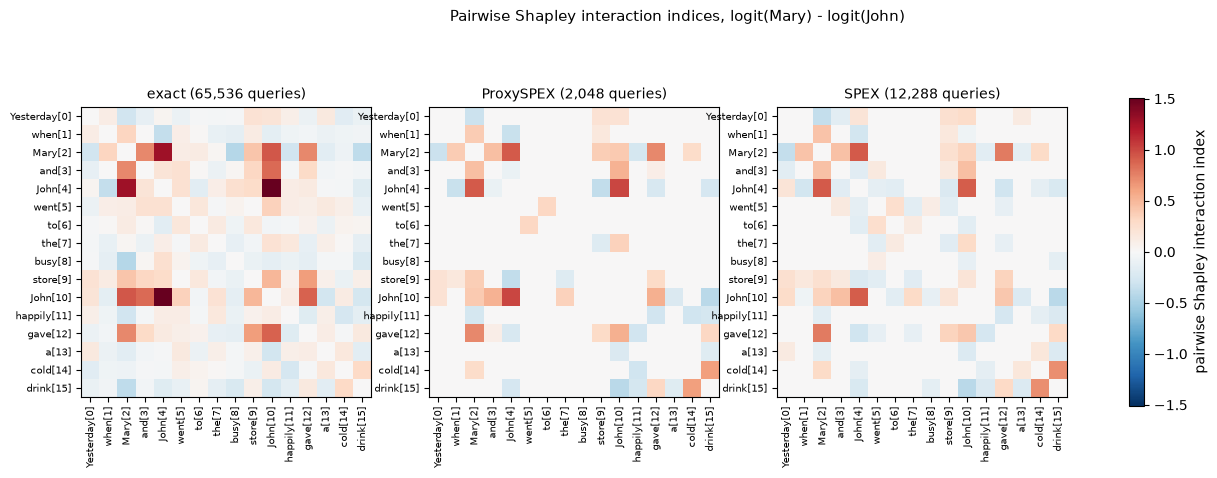

ProxySPEX (2,048 queries): correlation with exact pairwise SII over all 120 pairs = 0.800
SPEX (12,288 queries): correlation with exact pairwise SII over all 120 pairs = 0.798
method                        exact                     ProxySPEX                          SPEX
#1       John[4] × John[10] (+1.51)    John[4] × John[10] (+1.01)     Mary[2] × John[4] (+0.93)
#2        Mary[2] × John[4] (+1.28)     Mary[2] × John[4] (+0.92)    John[4] × John[10] (+0.91)
#3       Mary[2] × John[10] (+0.94)    Mary[2] × gave[12] (+0.73)    Mary[2] × gave[12] (+0.78)
#4      John[10] × gave[12] (+0.89)  cold[14] × drink[15] (+0.62)  cold[14] × drink[15] (+0.70)
#5        and[3] × John[10] (+0.85)   John[10] × gave[12] (+0.53)     and[3] × John[10] (+0.46)
Shapley values (logit diff):
           exact  ProxySPEX   SPEX
Mary[2]    3.628      3.269  3.345
John[4]   -0.666     -0.669 -0.726
John[10]  -0.624     -0.950 -0.787
cold[14]  -0.572     -0.586 -0.661
gave[12]   0.540      0.264  0.299
store,[9]

In [46]:
def pairwise_sii_matrix(sii: Spectrum, n: int) -> np.ndarray:
    mat = np.zeros((n, n))
    for T, v in sii.items():
        if len(T) == 2:
            mat[T[0], T[1]] = mat[T[1], T[0]] = v
    return mat


game = "logit diff"
exact_sii = shapley_interactions(array_to_spectrum(mobius_transform(exact_values[game])), max_order=2)
proxy_sii = shapley_interactions(fourier_to_mobius(ioi_spectra[game]["ProxySPEX"][budget_index][0]), max_order=2)
spex_sii = shapley_interactions(fourier_to_mobius(ioi_spectra[game]["SPEX"][-1][0]), max_order=2)
matrices = {
    "exact (65,536 queries)": pairwise_sii_matrix(exact_sii, n_words),
    "ProxySPEX (2,048 queries)": pairwise_sii_matrix(proxy_sii, n_words),
    "SPEX (12,288 queries)": pairwise_sii_matrix(spex_sii, n_words),
}
utils.plot_sii_heatmaps(matrices, words, "Pairwise Shapley interaction indices, logit(Mary) - logit(John)")

upper = np.triu_indices(n_words, 1)
pairs = [(i, j) for i, j in zip(*upper)]
for method in ["ProxySPEX (2,048 queries)", "SPEX (12,288 queries)"]:
    corr = np.corrcoef(matrices["exact (65,536 queries)"][upper], matrices[method][upper])[0, 1]
    print(f"{method}: correlation with exact pairwise SII over all {len(pairs)} pairs = {corr:.3f}")

table_rows = []
for name, sii in [("exact", exact_sii), ("ProxySPEX", proxy_sii), ("SPEX", spex_sii)]:
    top = sorted(((T, v) for T, v in sii.items() if len(T) == 2), key=lambda kv: -abs(kv[1]))[:5]
    table_rows.append({"method": name, **{f"#{r + 1}": f"{utils.support_label(T, words)} ({v:+.2f})" for r, (T, v) in enumerate(top)}})
print(pd.DataFrame(table_rows).set_index("method").T.to_string())

shapley_table = pd.DataFrame({
    name: [sii.get((i,), 0.0) for i in range(n_words)] for name, sii in [("exact", exact_sii), ("ProxySPEX", proxy_sii), ("SPEX", spex_sii)]
}, index=[f"{w}[{i}]" for i, w in enumerate(words)])
print("Shapley values (logit diff):")
print(shapley_table.sort_values("exact", key=abs, ascending=False).head(6).round(3).to_string())

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">ProxySPEX (2,048 queries): correlation with exact pairwise SII over all 120 pairs = 0.800
SPEX (12,288 queries): correlation with exact pairwise SII over all 120 pairs = 0.798
method                        exact                     ProxySPEX                          SPEX
#1       John[4] × John[10] (+1.51)    John[4] × John[10] (+1.01)     Mary[2] × John[4] (+0.93)
#2        Mary[2] × John[4] (+1.28)     Mary[2] × John[4] (+0.92)    John[4] × John[10] (+0.91)
#3       Mary[2] × John[10] (+0.94)    Mary[2] × gave[12] (+0.73)    Mary[2] × gave[12] (+0.78)
#4      John[10] × gave[12] (+0.89)  cold[14] × drink[15] (+0.62)  cold[14] × drink[15] (+0.70)
#5        and[3] × John[10] (+0.85)   John[10] × gave[12] (+0.53)     and[3] × John[10] (+0.46)
Shapley values (logit diff):
           exact  ProxySPEX   SPEX
Mary[2]    3.628      3.269  3.345
John[4]   -0.666     -0.669 -0.726
John[10]  -0.624     -0.950 -0.787
cold[14]  -0.572     -0.586 -0.661
gave[12]   0.540      0.264  0.299
store,[9]  0.515      0.235  0.041</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

**The headline interaction is found.** In the exact game the largest pairwise interaction is **John[4] × John[10]** (+1.51): the two mentions of John matter jointly, which is the
duplicate-name signal from the introduction. ProxySPEX (2,048 queries) ranks it first too, and SPEX ranks it second, just behind Mary × John[4], which is the exact game's #2. Both
methods' heatmaps reproduce the main structure: a block of positive interactions among Mary, the two Johns, *and* and *gave*, which are exactly the words the IOI task is about.

**The details are approximate.** The correlation with the exact pairwise SII over all 120 pairs is 0.80 for both methods. Both underestimate the largest interactions (ProxySPEX's
John × John is +1.01 against +1.51), both leave Mary × John[10] (exact #3) out of their top five, and both promote cold × drink into their top four, although it doesn't make the
exact top five. Remember that these explanations have $R^2 \approx 0.9$: the 10% of the variance they miss is spread over thousands of small higher-order terms, and the SII
redistributes higher-order terms down onto pairs, so pairwise SII is sensitive to exactly what a sparse explanation leaves out.

**Shapley values are robust.** All three agree that Mary dominates (3.63 exact; 3.27 and 3.35 from the sparse explanations), and on the signs of the next four words; smaller ones
like *store* are less reliable. The negative Shapley values for both Johns are worth a second look: averaged over coalitions, adding a John *lowers* the logit difference
(presumably by making " John" a more available answer), but the positive John × John interaction says that adding the *second* John helps Mary. A per-word attribution averages that
dependency away.
</details>

## Scaling up: a 27-word passage, queried live

Sixteen words was chosen so that we could check everything exactly. Now let's go past that: a longer version of the sentence with 27 words. There are $2^{27} \approx 1.3 \times
10^8$ masks, so no exact reference; we judge every explanation by its $R^2$ on 2,000 **held-out** random masks, queried live. Each method gets the same budget as SPEX at $b = 6$.

Two practical details. First, SPEX's designs contain repeated masks (e.g. the all-zeros mask appears in every hash), so the number of *distinct* forward passes is a bit lower than
the number of queries; the `CachedValueFunction` wrapper below evaluates each distinct mask once and counts them. Second, both read-outs come from the same forward pass, so we
cache both and run each method on each read-out without extra model calls.

In [47]:
class CachedValueFunction:
    """Wraps a value function so that each distinct mask is evaluated (by the model) only once."""

    def __init__(self, f: Callable[[np.ndarray], np.ndarray]):
        self.f, self.cache = f, {}

    def __call__(self, masks: np.ndarray) -> np.ndarray:
        masks = np.asarray(masks, dtype=np.int64)
        keys = [row.tobytes() for row in np.packbits(masks.astype(np.uint8), axis=1)]
        first_row = {}
        for row, key in enumerate(keys):
            if key not in self.cache and key not in first_row:
                first_row[key] = row
        if first_row:
            new_values = self.f(masks[list(first_row.values())])
            self.cache.update(zip(first_row, new_values))
        return np.array([self.cache[key] for key in keys])

    @property
    def n_evaluated(self) -> int:
        return len(self.cache)

27 words; full sentence: logit diff = 2.69, p(Mary) = 0.463


3072 queries per method; 8,112 distinct forward passes in total, 14s


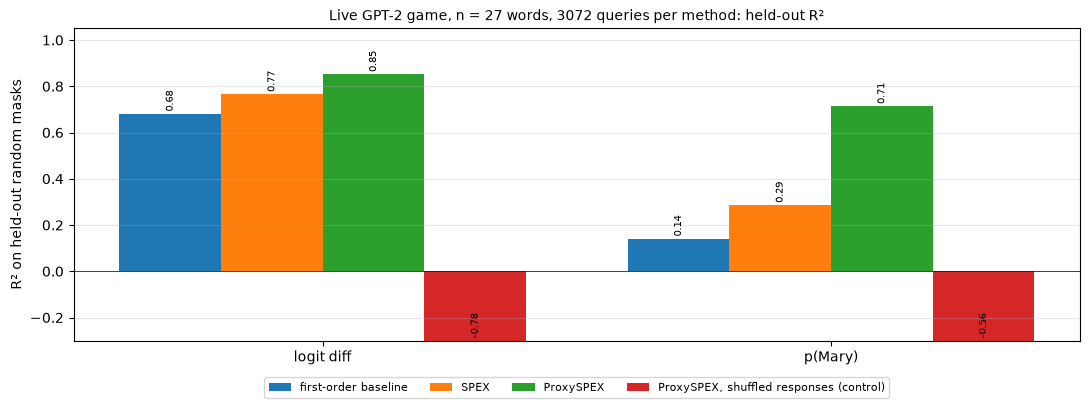

            first-order baseline   SPEX  ProxySPEX  ProxySPEX, shuffled responses (control)
logit diff                 0.681  0.766      0.852                                   -0.781
p(Mary)                    0.141  0.286      0.714                                   -0.565
ProxySPEX's largest pairwise SII (logit diff):
  +1.124  Mary[3] × sandwich[26]
  +0.700  Mary[3] × John[5]
  +0.668  John[5] × John[17]
  +0.584  Mary[3] × gave[19]
  -0.537  John[5] × sandwich[26]
  -0.479  and[23] × sandwich[26]


In [48]:
LONG_TEXT = ("Yesterday afternoon, when Mary and John finally went to the busy little store near the old station, "
             "John happily gave a cold drink and a small sandwich")
long_words, long_tokens, long_token_to_word = utils.tokenize_words(model, LONG_TEXT, " to")
n_long = len(long_words)
long_both = CachedValueFunction(make_value_function(model, long_tokens, long_token_to_word, ioi_readouts))
print(f"{n_long} words; full sentence: logit diff = {long_both(np.ones((1, n_long)))[0, 0]:.2f}, "
      f"p(Mary) = {long_both(np.ones((1, n_long)))[0, 1]:.3f}")

long_test = np.random.default_rng(99).integers(0, 2, size=(2000, n_long))
live_results, live_spectra = {}, {}
start = time.time()
for column, name in enumerate(["logit diff", "p(Mary)"]):
    f_long = lambda X, c=column: long_both(X)[:, c]  # noqa: E731
    y_test = f_long(long_test)
    spex_spectrum, spex_queries = spex(f_long, n_long, b=6, t=3, chase_depth=3, seed=0)
    budget = len(spex_queries)
    proxy_spectrum, X_proxy = proxyspex(f_long, n_long, budget, seed=0)
    shuffle_rng = np.random.default_rng(1)
    shuffled_spectrum, _ = proxyspex(lambda X: shuffle_rng.permutation(f_long(X)), n_long, budget, seed=0)
    live_results[name] = {
        "first-order baseline": faithfulness_r2(first_order_baseline(X_proxy, f_long(X_proxy)), long_test, y_test),
        "SPEX": faithfulness_r2(spex_spectrum, long_test, y_test),
        "ProxySPEX": faithfulness_r2(proxy_spectrum, long_test, y_test),
        "ProxySPEX, shuffled responses (control)": faithfulness_r2(shuffled_spectrum, long_test, y_test),
    }
    live_spectra[name] = proxy_spectrum
print(f"{budget} queries per method; {long_both.n_evaluated:,} distinct forward passes in total, {time.time() - start:.0f}s")
utils.plot_method_bars(live_results, f"Live GPT-2 game, n = {n_long} words, {budget} queries per method: held-out R²", ylim=(-0.3, 1.05))
print(pd.DataFrame(live_results).T.round(3).to_string())

proxy_sii_long = shapley_interactions(fourier_to_mobius(live_spectra["logit diff"]), max_order=2)
print("ProxySPEX's largest pairwise SII (logit diff):")
for T, v in sorted(((T, v) for T, v in proxy_sii_long.items() if len(T) == 2), key=lambda kv: -abs(kv[1]))[:6]:
    print(f"  {v:+.3f}  {utils.support_label(T, long_words)}")

<details>
<summary>Expected output (timings will vary)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">27 words; full sentence: logit diff = 2.69, p(Mary) = 0.463
3072 queries per method; 8,112 distinct forward passes in total, 42s
            first-order baseline   SPEX  ProxySPEX  ProxySPEX, shuffled responses (control)
logit diff                 0.681  0.766      0.852                                   -0.781
p(Mary)                    0.141  0.286      0.714                                   -0.565
ProxySPEX's largest pairwise SII (logit diff):
  +1.124  Mary[3] × sandwich[26]
  +0.700  Mary[3] × John[5]
  +0.668  John[5] × John[17]
  +0.584  Mary[3] × gave[19]
  -0.537  John[5] × sandwich[26]
  -0.479  and[23] × sandwich[26]</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The ordering from the 16-word game holds up on a passage with $2^{27}$ masks: ProxySPEX is the most faithful on both read-outs (held-out $R^2$ of 0.85 and 0.71), SPEX is in between
(0.77 and 0.29), the first-order baseline is lowest (0.68 and 0.14), and the shuffled control is far below zero. As before, the gap between first-order and ProxySPEX is much larger
for the probability (0.14 → 0.71) than for the logit difference (0.68 → 0.85). SPEX suffers most on `p(Mary)`, whose spectrum is the least sparse; and with $n = 27$ the BCH code
still saves little (16 delays per hash against 28), so its structured queries buy it nothing here.

(By coincidence, the full passage has the same logit difference as the 16-word sentence to two decimal places, 2.69; its probability, 0.46, is different. It's the test of
`masked_final_logits` that guarantees the masking is right.)

The interactions tell a recognisably similar story with one new protagonist. Mary × John[5], **John[5] × John[17]** (the duplicated name again) and Mary × gave are all there. The
new top interaction, Mary × sandwich, involves the last word before the final " to". One plausible reading: deleting *sandwich* leaves "...a cold drink and a small to", where " to"
no longer reads as the start of the recipient phrase, so the evidence for Mary only counts when the phrase is intact. If that's right, it's an interaction about *grammaticality*
rather than about who received the drink, which is a useful reminder that deletion games probe the edited text the model sees, not just "which facts it uses". (Testing this reading
with a few hand-made masks is a good exercise.)
</details>

## Try it yourself

`explain_prompt` below runs ProxySPEX live on any prompt you like, compares it with the first-order baseline on held-out masks, and prints the largest pairwise interactions and
Shapley values. The words of `text` are the features; `final` is always kept. With a `contrast` token, the read-out is the logit difference `target - contrast`; without one, it's
the log-probability of `target`. Both tokens must be single tokens (with their leading space).

Some things to try:

- A factual prompt, e.g. `"The famous tower that Gustave Eiffel designed for the world fair is located in the city of"` with target `" Paris"`. Which words interact?
- Negation (the default example below): `"The food at this restaurant was not good at all, and honestly the service"` with final `" was"`, target `" terrible"` and contrast `" great"`. Does GPT-2 Small show a `not × good` interaction, and does the first-order baseline do noticeably worse here?
- Induction: a prompt where a rare word appears early and is copied later. Copying requires two pieces of context at once, which should show up as a strong pairwise interaction.
- Swap the read-out (add or remove `contrast`) for the same prompt, and see how the interaction structure changes, as it did for IOI.

Remember to look at the $R^2$ before reading the interactions: an explanation that predicts the model badly isn't telling you much about it.

In [49]:
def explain_prompt(text: str, final: str, target: str, contrast: str | None = None, budget: int = 2048, seed: int = 0) -> None:
    words_, tokens_, token_to_word_ = utils.tokenize_words(model, text, final)
    target_id = model.to_single_token(target)
    if contrast is None:
        readout = lambda logits: logits.log_softmax(-1)[:, target_id]  # noqa: E731
    else:
        contrast_id = model.to_single_token(contrast)
        readout = lambda logits: logits[:, target_id] - logits[:, contrast_id]  # noqa: E731
    f = CachedValueFunction(make_value_function(model, tokens_, token_to_word_, readout))
    n = len(words_)
    full = f(np.ones((1, n), dtype=int))[0]
    spectrum, X = proxyspex(f, n, budget, seed=seed)
    test = np.random.default_rng(seed + 1).integers(0, 2, size=(1000, n))
    y_test = f(test)
    print(f"{n} words, read-out on the full prompt = {full:.3f}; {f.n_evaluated} forward passes")
    print(f"held-out R²: ProxySPEX = {faithfulness_r2(spectrum, test, y_test):.3f} ({len(spectrum)} terms), "
          f"first-order baseline = {faithfulness_r2(first_order_baseline(X, f(X)), test, y_test):.3f}")
    sii = shapley_interactions(fourier_to_mobius(spectrum), max_order=2)
    print("largest pairwise Shapley interactions:")
    for T, v in sorted(((T, v) for T, v in sii.items() if len(T) == 2), key=lambda kv: -abs(kv[1]))[:6]:
        print(f"  {v:+.3f}  {utils.support_label(T, words_)}")
    print("largest Shapley values:")
    for T, v in sorted(((T, v) for T, v in sii.items() if len(T) == 1), key=lambda kv: -abs(kv[1]))[:6]:
        print(f"  {v:+.3f}  {utils.support_label(T, words_)}")


explain_prompt(
    "The food at this restaurant was not good at all, and honestly the service",
    final=" was",
    target=" terrible",
    contrast=" great",
)

14 words, read-out on the full prompt = 1.239; 2784 forward passes
held-out R²: ProxySPEX = 0.909 (60 terms), first-order baseline = 0.549
largest pairwise Shapley interactions:
  +1.992  not[6] × good[7]
  +1.242  not[6] × service[13]
  +1.182  the[12] × service[13]
  -1.105  not[6] × honestly[11]
  +0.734  was[5] × not[6]
  +0.690  not[6] × and[10]
largest Shapley values:
  +2.185  not[6]
  +0.420  honestly[11]
  +0.387  food[1]
  +0.326  was[5]
  -0.293  the[12]
  +0.247  and[10]


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">14 words, read-out on the full prompt = 1.239; 2784 forward passes
held-out R²: ProxySPEX = 0.910 (60 terms), first-order baseline = 0.549
largest pairwise Shapley interactions:
  +1.989  not[6] × good[7]
  +1.238  not[6] × service[13]
  +1.178  the[12] × service[13]
  -1.104  not[6] × honestly[11]
  +0.725  was[5] × not[6]
  +0.693  not[6] × and[10]
largest Shapley values:
  +2.189  not[6]
  +0.414  honestly[11]
  +0.387  food[1]
  +0.296  was[5]
  -0.291  the[12]
  +0.230  and[10]</pre>

</details>

The negation example works nicely. The read-out, `logit(" terrible") - logit(" great")`, is 1.24 on the full prompt. ProxySPEX explains it with $R^2 = 0.91$ on held-out masks,
against 0.55 for the best-fitting additive model, so this behaviour is substantially interactive. The top interaction is **not × good** (+1.99): *not* pushes towards *terrible*
much more when *good* is there to be negated, and *not* also has by far the largest Shapley value. Other entries are less obvious: what's going on with not × honestly (−1.10), or
the × service? Look at a few hand-made masks (with your `make_value_function`) before believing any story about them.

## Summary of 5️⃣

- On the exact 16-word GPT-2 game, interaction explanations are much more faithful than any additive one can be: for `p(Mary)`, 0.78-0.82 (ProxySPEX, 2-4k queries) against an additive ceiling of 0.24; for the logit difference, 0.91-0.92 against 0.80.
- ProxySPEX is far more query-efficient than SPEX at this scale ($n$ = 16 and 27), consistent with the ProxySPEX paper. SPEX's strengths (exactness on sparse games, a query cost logarithmic in $n$, no hierarchy assumption) need larger $n$ and sparser spectra to pay off.
- The specific interactions matter: relabelling them (same number, same degrees) loses most of their benefit, and training on shuffled responses gives explanations far worse than predicting the mean.
- Both methods recover the duplicated-name interaction (John × John) that the IOI circuit relies on, and agree with the exact Shapley values; finer pairwise structure is only approximately right (correlation 0.80 with the exact pairwise SII).
- The exact Shapley values, used as an additive model, are not faithful under masking ($R^2$ of 0.04 and −18.5). Judge an explanation by its held-out faithfulness, not by whether its numbers look reasonable.

**Limitations.** A deletion game is one particular intervention, and an interaction in it is a statement about the model's behaviour on edited text, not about its internal
mechanism. Our ProxySPEX uses scikit-learn gradient boosting with fixed hyperparameters and a cap on the number of terms, rather than the paper's tuned LightGBM; our SPEX uses a
simple Chase decoder and no final refit. All GPT-2 results come from two IOI-style prompts and one negation prompt on one small model, so treat the comparisons as illustrations of
how the methods behave, not as a benchmark.

# ☆ Bonus

## Test the hierarchy hypothesis on GPT-2

ProxySPEX's design rests on the claim that interactions in LLMs are *hierarchical*: an important interaction $S$ tends to come with important lower-order subsets. You have the
exact spectrum, so you can test this directly rather than trusting it. Some ways to operationalise it:

- For each of the 20 largest Fourier coefficients of degree $\ge 2$, compute the rank (by magnitude) of each of its subsets of size $|S| - 1$. Compare with the ranks you'd expect for random subsets of the same sizes.
- Fit ProxySPEX with `max_depth=2` (trees that can only represent pairs) on the `p(Mary)` game and see how much of the degree-3 energy it still recovers, via the refit. If interactions were not hierarchical, shallow trees would never propose the right degree-3 supports.
- Construct a version of the IOI game that *isn't* hierarchical, by multiplying the value function by a parity of two irrelevant words (e.g. `χ_{the, a}`), and rerun the section 4️⃣ comparison. Which method survives?

## Implement Berlekamp-Massey yourself

We gave you `berlekamp_massey`. Re-implement it from the description in the aside (or from Massey's 1969 paper, *Shift-register synthesis and BCH decoding*), and check it against
the provided version on random syndromes. Then try **Peterson's algorithm**, which solves Newton's identities directly as a $t \times t$ linear system over $\mathrm{GF}(2^m)$:
simpler for $t \le 3$, but $O(t^3)$ instead of $O(t^2)$.

## Soft decoding and the γ threshold

Our Chase decoder tries at most $1 + c + \binom{c}{2}$ bit flips. On the GPT-2 games, how do SPEX's faithfulness and number of recovered terms change with `chase_depth` in $\{0, 3,
6\}$ and `gamma` in $\{0.3, 0.6, 0.9\}$? Can you find settings where a *more* permissive singleton test makes the explanation worse, because it accepts collisions as singletons?

## Compare with the reference implementations

The authors' package is [`spectralexplain`](https://github.com/basics-lab/spectral-explain) (SPEX via `sparse-transform`'s BCH and peeling code; ProxySPEX via LightGBM), and `shapiq` (≥ 1.5) includes a maintained `ProxySPEX` approximator. If you install them in a separate environment, compare their spectra with yours on the planted games of section 4️⃣. Known differences worth checking: the reference ProxySPEX selection uses a strict inequality at the 95% energy boundary and doesn't explicitly keep the constant (on a pure-parity game this selects an empty spectrum and the refit fails); the paper's SPEX tables show the Fourier-to-Shapley conversion without its factor of $-2$ (appendix C has it right: $\phi_i = -2\sum_{S \ni i,\, |S| \text{ odd}} F(S)/|S|$); and the paper's message-passing formula sums the messages a support receives, while the code averages them. Can you verify the Shapley-value formula from your `fourier_to_mobius` and `shapley_interactions`?

## Other interaction indices

Your Möbius coefficients give every other index too. Implement the **Banzhaf interaction index** ($\sum_{S \supseteq T} m(S) / 2^{|S| - |T|}$), the **Shapley-Taylor** index and
**Faith-Shapley** (both defined in [16.5]) from a sparse Möbius spectrum, and compare their top pairs on the IOI game. Which indices agree, and why?

## Masking is a modelling choice

Repeat section 2️⃣ with a different intervention: replace masked words with a fixed placeholder token (e.g. `" _"`), or keep the attention mask but *don't* shift positions (pass
explicit position ids through a hook). How do the degree energies change? An interaction between two words under deletion is not the same claim as an interaction under replacement,
and neither is a claim about the model's internal mechanism.

## From interactions to circuits

The John × John interaction is a behavioural fingerprint of the duplicate-token signal. Use activation patching ([1.4.1]) to test it mechanistically: does patching the S-inhibition
heads' outputs from the "both Johns present" run into a run with one John deleted restore the logit difference? Section [16.8] goes further in comparing Shapley-style attributions
with patching.

## Further reading

- Kang, Butler, Agarwal, Erginbas, Pedarsani, Ramchandran & Yu (2025), [*SPEX: Scaling Feature Interaction Explanations for LLMs*](https://proceedings.mlr.press/v267/kang25a.html), ICML. Section 5 and appendix A describe the sampling design and decoder; appendix C the conversions to interaction indices.
- Butler, Agarwal, Kang, Erginbas, Yu & Ramchandran (2025), [*ProxySPEX: Inference-Efficient Interpretability via Sparse Feature Interactions in LLMs*](https://papers.neurips.cc/paper_files/paper/2025/hash/68dced1638d71d4d21598f79ae91262e-Abstract-Conference.html), NeurIPS. The hierarchy observation and the tree-extraction approach.
- Li, Bradley & Ramchandran (2015), [*SPRIGHT: A Fast and Robust Framework for Sparse Walsh-Hadamard Transform*](https://arxiv.org/abs/1508.06336). The aliasing-plus-peeling framework SPEX builds on.
- Gorji, Amrollahi & Krause (2024), [*Amortized SHAP values via sparse Fourier function approximation*](https://arxiv.org/abs/2410.06300). The tree-to-Fourier extraction used by ProxySPEX.
- O'Donnell (2014), [*Analysis of Boolean Functions*](https://arxiv.org/abs/2105.10386). Chapters 1-3 for everything about Fourier expansions on the hypercube, including why low-degree concentration is so common.
- Grabisch, Marichal & Roubens (2000), *Equivalent representations of set functions*, Mathematics of Operations Research. The Möbius-to-interaction-index conversions.
- Muschalik et al. (2024), [*shapiq: Shapley Interactions for Machine Learning*](https://arxiv.org/abs/2410.01649). The library behind the cross-check in section 1️⃣.